# Exploración de noticias de la Universidad de Sonora (2015–2026)

Primer acercamiento a las noticias extraídas del portal de la Unison con `scraper_unison.py`.

1. **Vistazo rápido:** cuántas noticias tenemos y qué contiene cada columna.
2. **Estadísticas generales:** tamaño de las notas, noticias por año y por mes, autores.
3. **Nubes de palabras:** primero con todas las palabras y después quitando las *stopwords*, para comparar; al final, una nube por mes.
4. **Departamentos:** qué departamentos aparecen más en las noticias y cómo cambia su presencia con los años.
5. **Cambios de vocabulario:** expresiones que aparecen o desaparecen con los años (pandemia, estructura de la universidad).
6. **Palabras características de cada año:** TF-IDF, tomando cada año como un documento.

## 1. Librerías

In [1]:
import json
import math
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords

## 2. Carga de datos

El scraper guarda una noticia por línea en formato JSONL. Lo leemos línea por línea:
si el scraper sigue corriendo, la última línea puede estar a medio escribir y simplemente la saltamos.

In [2]:
RUTA = "data/raw/noticias_unison.jsonl"

registros = []
with open(RUTA, encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

datos = pd.DataFrame(registros)
print("Registros leídos:", len(datos))
datos["estado"].value_counts()

Registros leídos: 20638


estado
ok       19925
vacia      713
Name: count, dtype: int64

Cada registro tiene un `estado`:
- `ok`: noticia descargada correctamente.
- `vacia`: el ID no existe en el sitio (notas borradas o saltos en la numeración).
- `error`: falló la descarga (el scraper los reintenta en la siguiente corrida).

Nos quedamos solo con las noticias válidas y preparamos las columnas de fecha.

In [3]:
noticias = datos[datos["estado"] == "ok"].copy()
noticias = noticias.drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)

noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["mes"] = noticias["fecha"].dt.month
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias["n_parrafos"] = noticias["n_parrafos"].astype(int)

columnas = ["id", "fecha", "anio", "mes", "titulo", "autor", "texto", "n_parrafos", "n_palabras", "url"]
noticias = noticias[columnas]
noticias.head()

,id,fecha,anio,mes,titulo,autor,texto,n_parrafos,n_palabras,url
0,18387,2015-01-02,2015,1,Presenta DSD la Universidad resumen especial d...,NaN,"Durante el 2014, la comunidad estudiantil, aca...",6,230,https://www.unison.mx/nota/?idnoti=18387
1,18388,2015-01-02,2015,1,Impulsar geoturismo como potencial de desarrol...,NaN,El geoturismo en Sonora alberga un gran potenc...,12,509,https://www.unison.mx/nota/?idnoti=18388
2,18389,2015-01-03,2015,1,Tarde de buen cine mexicano este 4 de enero de...,NaN,Para iniciar los domingos de entretenimiento f...,17,802,https://www.unison.mx/nota/?idnoti=18389
3,18390,2015-01-03,2015,1,Se espera mayor movilidad del dólar y crecimie...,NaN,Relativamente favorables se muestran las expec...,9,384,https://www.unison.mx/nota/?idnoti=18390
4,18391,2015-01-03,2015,1,Será en línea registro para examen de colocaci...,NaN,¿Planeas estudiar inglés o algún otro idioma e...,12,556,https://www.unison.mx/nota/?idnoti=18391


## 3. Vistazo rápido

In [4]:
print("Noticias válidas:", len(noticias))
print("IDs vacíos (no existen en el sitio):", (datos["estado"] == "vacia").sum())
print("Errores de descarga:", (datos["estado"] == "error").sum())
print("Primera noticia:", noticias["fecha"].min().date())
print("Última noticia:", noticias["fecha"].max().date())

Noticias válidas: 19925
IDs vacíos (no existen en el sitio): 713
Errores de descarga: 0
Primera noticia: 2015-01-02
Última noticia: 2026-10-29


In [5]:
noticias.info()

<class 'pandas.DataFrame'>
RangeIndex: 19925 entries, 0 to 19924
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          19925 non-null  int64         
 1   fecha       19925 non-null  datetime64[us]
 2   anio        19925 non-null  int32         
 3   mes         19925 non-null  int32         
 4   titulo      19925 non-null  str           
 5   autor       11154 non-null  str           
 6   texto       19925 non-null  str           
 7   n_parrafos  19925 non-null  int64         
 8   n_palabras  19925 non-null  int64         
 9   url         19925 non-null  str           
dtypes: datetime64[us](1), int32(2), int64(3), str(4)
memory usage: 1.4 MB


¿Qué columnas tienen valores vacíos? Se espera que falte el `autor` en las notas más antiguas.

In [6]:
noticias.isna().sum()

id               0
fecha            0
anio             0
mes              0
titulo           0
autor         8771
texto            0
n_parrafos       0
n_palabras       0
url              0
dtype: int64

Una noticia completa, para ver cómo luce el texto:

In [7]:
ejemplo = noticias.iloc[-1]
print(ejemplo["fecha"].date(), "|", ejemplo["autor"])
print(ejemplo["titulo"])
print()
print(ejemplo["texto"][:1500])

2026-10-29 | Paula Trespalacios Argain
Celebra la Unison la edición 25 de su tradicional Procesión de Día de Muertos

Con el humor, la sátira y las expresiones plásticas que caracterizan las tradiciones mexicanas, la Universidad de Sonora celebró su tradicional Procesión de Día de Muertos, actividad artística organizada por el Departamento de Bellas Artes que este 29 de octubre llegó a su edición número 25.
Inspirada en la estética y el universo gráfico del grabador mexicano José Guadalupe Posada, la manifestación artística reunió a más de 200 participantes, entre estudiantes y académicos, a quienes se sumaron cientos de transeúntes, integrantes de la comunidad estudiantil y familias durante el recorrido por el campus Hermosillo y sus alrededores.
Un itinerario de sátira, música y expresión escénica
Desde la entrada principal del Centro de las Artes, el contingente inició un recorrido con cinco presentaciones artísticas en distintos espacios universitarios, con el Departamento de Lengu

## 4. Estadísticas generales

### 4.1 Tamaño de las noticias

In [8]:
noticias[["n_palabras", "n_parrafos"]].describe().round(1)

,n_palabras,n_parrafos
count,19925.0,19925.0
mean,469.1,10.7
std,220.5,7.4
min,0.0,0.0
25%,325.0,7.0
50%,430.0,9.0
75%,565.0,13.0
max,4041.0,493.0


In [9]:
print("Total de palabras en el corpus:", noticias["n_palabras"].sum())

Total de palabras en el corpus: 9346735


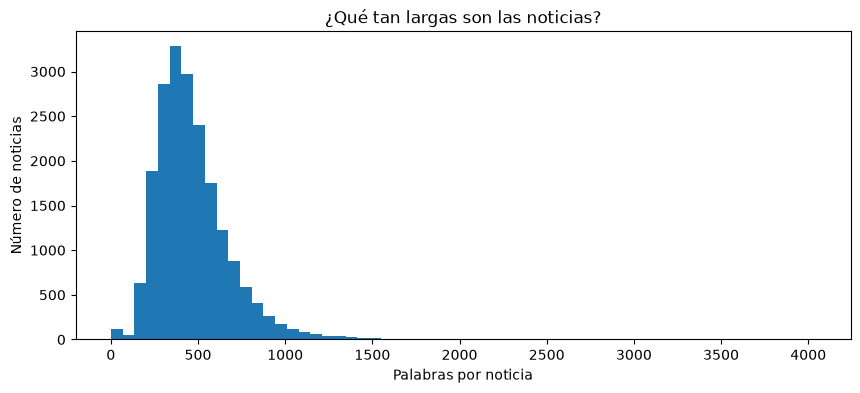

In [10]:
plt.figure(figsize=(10, 4))
plt.hist(noticias["n_palabras"], bins=60)
plt.title("¿Qué tan largas son las noticias?")
plt.xlabel("Palabras por noticia")
plt.ylabel("Número de noticias")
plt.show()

Las noticias más cortas y más largas, para detectar casos raros:

In [11]:
noticias.nsmallest(5, "n_palabras")[["id", "fecha", "titulo", "n_palabras"]]

,id,fecha,titulo,n_palabras
8539,27256,2018-11-09,CONSULTA LA GACETA EDICIÃ?N INTERNACIONAL,0
9244,28010,2019-04-02,.,0
12418,31397,2021-10-02,.,0
18479,37554,2025-08-18,Proceso de designación de la persona titular d...,0
9282,28053,2019-04-23,.,1


In [12]:
noticias.nlargest(5, "n_palabras")[["id", "fecha", "titulo", "n_palabras"]]

,id,fecha,titulo,n_palabras
12000,30972,2021-05-26,Gilberto Gutiérrez Quiroz: su notable e histór...,4041
10954,29839,2020-05-18,Las lecciones de la pandemia: una visión unive...,3826
11515,30454,2020-12-31,"Premios Anuales 2020: espíritu, visión de futu...",3785
10958,29843,2020-05-19,Las lecciones de la pandemia: una visión unive...,3658
12945,31933,2022-01-18,"Pandemia, cambio climático y otros factores en...",3108


Hay algunas "noticias" casi vacías: publicaciones con título `.` o avisos que solo tenían una imagen
(p. ej. *"Cartelera de Eventos del 80 Aniversario"*). No son noticias reales y todas tienen 0 o 1 palabra,
así que quitamos las que tienen menos de 30 palabras.

In [13]:
casi_vacias = noticias[noticias["n_palabras"] < 30]
print("Notas casi vacías:", len(casi_vacias))

noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)
print("Noticias que quedan:", len(noticias))

Notas casi vacías: 112
Noticias que quedan: 19813


### 4.2 Noticias por año

In [14]:
por_anio = noticias["anio"].value_counts().sort_index()
por_anio

anio
2015    2377
2016    2337
2017    2052
2018    2058
2019    1705
2020     946
2021    1356
2022    1613
2023    1650
2024    1457
2025    1313
2026     949
Name: count, dtype: int64

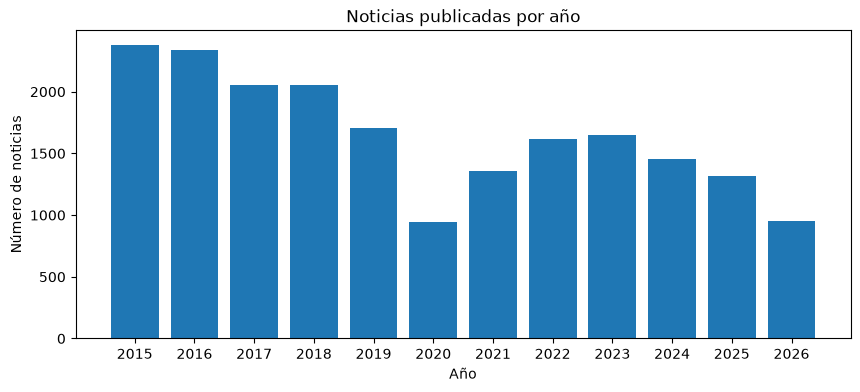

In [15]:
plt.figure(figsize=(10, 4))
plt.bar(por_anio.index, por_anio.values)
plt.title("Noticias publicadas por año")
plt.xlabel("Año")
plt.ylabel("Número de noticias")
plt.xticks(por_anio.index)
plt.show()

*Ojo:* el último año está incompleto (el scraping se hizo a finales de octubre de 2026).
Para compararlo con los demás, contamos en todos los años solo las noticias publicadas
hasta el mismo día del año que la última nota.

In [16]:
ultima_fecha = noticias["fecha"].max()
# day_of_year: número de día dentro del año (1 = 1 de enero)
hasta_mismo_dia = noticias[noticias["fecha"].dt.day_of_year <= ultima_fecha.day_of_year]

print("Noticias del 1 de enero al", ultima_fecha.strftime("%d/%m"), "de cada año:")
hasta_mismo_dia["anio"].value_counts().sort_index()

Noticias del 1 de enero al 29/10 de cada año:


anio
2015    1902
2016    1898
2017    1658
2018    1697
2019    1333
2020     697
2021    1058
2022    1313
2023    1350
2024    1174
2025    1098
2026     949
Name: count, dtype: int64

### 4.3 ¿Menos noticias, pero más largas?

Que haya menos noticias no significa necesariamente que se escriba menos.
Revisamos el tamaño de las notas y el total de palabras publicadas cada año.

In [17]:
por_anio_tamano = noticias.groupby("anio").agg(
    noticias=("id", "count"),
    mediana_palabras=("n_palabras", "median"),
    total_palabras=("n_palabras", "sum"),
)
por_anio_tamano

,noticias,mediana_palabras,total_palabras
anio,,,
2015,2377,371.0,926465
2016,2337,382.0,922266
2017,2052,375.0,819001
2018,2058,382.5,846996
2019,1705,435.0,805061
2020,946,518.0,547253
2021,1356,587.0,859873
2022,1613,537.0,968084
2023,1650,478.0,873013


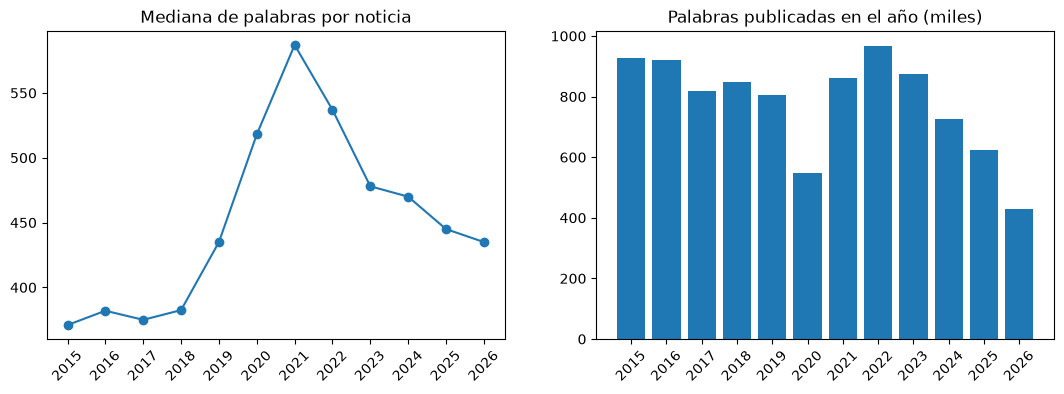

In [18]:
fig, (izquierda, derecha) = plt.subplots(1, 2, figsize=(13, 4))

izquierda.plot(por_anio_tamano.index, por_anio_tamano["mediana_palabras"], marker="o")
izquierda.set_title("Mediana de palabras por noticia")
izquierda.set_xticks(por_anio_tamano.index)
izquierda.tick_params(axis="x", rotation=45)

derecha.bar(por_anio_tamano.index, por_anio_tamano["total_palabras"] / 1000)
derecha.set_title("Palabras publicadas en el año (miles)")
derecha.set_xticks(por_anio_tamano.index)
derecha.tick_params(axis="x", rotation=45)

plt.show()

### 4.4 Noticias por mes

Sumamos todos los años, pero dejamos fuera el último porque está incompleto
(si no, noviembre y diciembre saldrían artificialmente bajos).

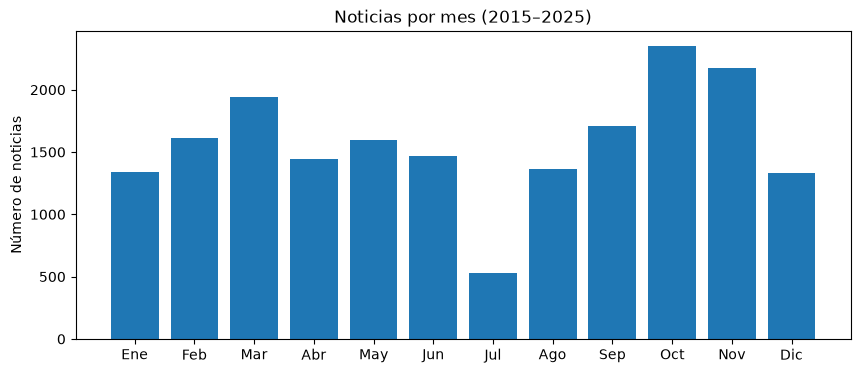

In [19]:
ultimo_anio = noticias["anio"].max()
anios_completos = noticias[noticias["anio"] < ultimo_anio]

por_mes = anios_completos["mes"].value_counts().sort_index()
por_mes = por_mes.reindex(range(1, 13), fill_value=0)  # por si algún mes no tiene notas

nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

plt.figure(figsize=(10, 4))
plt.bar(nombres_meses, por_mes.values)
plt.title(f"Noticias por mes ({anios_completos['anio'].min()}–{anios_completos['anio'].max()})")
plt.ylabel("Número de noticias")
plt.show()

**¿El pico de octubre es por el aniversario?** La Unison se fundó el 12 de octubre de 1942.
Si la hipótesis es correcta, la palabra *aniversario* debería aparecer mucho más en las notas de octubre.
Porcentaje de las noticias de cada mes que la mencionan:

In [20]:
noticias["menciona_aniversario"] = noticias["texto"].str.contains("aniversario", case=False)

aniversario_por_mes = noticias.groupby("mes")["menciona_aniversario"].mean() * 100
aniversario_por_mes.index = nombres_meses
aniversario_por_mes.round(1)

Ene     3.1
Feb     3.1
Mar     4.4
Abr     4.6
May     2.7
Jun     3.1
Jul     1.6
Ago     2.0
Sep     7.2
Oct    19.0
Nov    13.7
Dic     4.1
Name: menciona_aniversario, dtype: float64

### 4.5 Autores

In [21]:
# Algunas firmas vienen como "Por Luis Mendoza": quitamos el "Por "
noticias["autor"] = noticias["autor"].str.replace(r"^Por ", "", regex=True)

noticias["autor"].value_counts().head(15)

autor
Elías Quijada                1964
Jesús Alberto Rubio          1882
Beatriz Espinoza             1796
Paula Trespalacios Argain    1783
Lin Mendivil Alvarado         786
Olivia Paredes                624
Aleyda Gutiérrez Guerrero     417
Haydee Gaxiola                398
Denice López Martínez         366
Luis Mendoza                  299
Haydeé Gaxiola                149
Beatriz Angélica Espinoza     125
Jonathan Castellón Flores      94
Armando Zamora                 66
Karla Valenzuela               51
Name: count, dtype: int64

Un mismo reportero puede aparecer escrito de varias formas
(p. ej. *Beatriz Espinoza* / *Beatriz Angélica Espinoza*). Por ahora no lo corregimos
porque el autor no es el foco del análisis.

¿Desde cuándo las notas incluyen el nombre del reportero? Proporción de notas con autor por año:

In [22]:
noticias["tiene_autor"] = noticias["autor"].notna()
noticias.groupby("anio")["tiene_autor"].mean().round(2)

anio
2015    0.00
2016    0.00
2017    0.00
2018    0.38
2019    0.93
2020    0.94
2021    0.94
2022    0.95
2023    0.97
2024    0.97
2025    0.95
2026    0.88
Name: tiene_autor, dtype: float64

En 2026 la proporción baja. ¿Dejaron de firmar las notas o el scraper no reconoce la firma?
Revisamos la primera línea de las notas sin autor desde 2018:

In [23]:
sin_autor = noticias[noticias["autor"].isna() & (noticias["anio"] >= 2018)]
primera_linea = sin_autor["texto"].str.split("\n").str[0]

print("Notas sin autor desde 2018:", len(sin_autor))
primera_linea.value_counts().head(8)

Notas sin autor desde 2018: 1893


texto
Redacción                      288
Paula Trespalacios Argain.      16
Jesús Alberto Rubio.             8
Jesús alberto Rubio              7
Luz Haydee Gaxiola Cabrera.      7
Luz Haydeé Gaxiola Cabrera.      6
(Redacción)                      5
Redacción.                       5
Name: count, dtype: int64

La firma sí está, pero el scraper no la reconoce en tres casos: **"Redacción"** (una sola palabra;
la regla de `parece_autor` pide al menos dos), **nombres con punto final** (*"Paula Trespalacios Argain."*)
y **nombres con una palabra en minúscula** (*"Jesús alberto Rubio"*). Por eso esa línea se quedó
dentro del texto. Son ~350 notas y no afectan el resto del análisis, pero conviene ajustar la regla en el scraper.

### Observaciones de las estadísticas

- **Volumen:** ~19,800 noticias entre enero de 2015 y octubre de 2026, con una mediana de ~430 palabras por nota.
- **Por año:** la producción baja de ~2,400 notas (2015) a ~1,700 (2019) y se desploma a ~950 en **2020**,
  el año de la pandemia. Se recupera hasta 2023 (~1,650) y vuelve a bajar desde 2024.
  Al mismo día del año, **2026 lleva 949 notas contra 1,098 de 2025 (−14%)**: va camino a ser el año
  con menos noticias después de 2020.
- **Menos notas, pero más largas:** la mediana sube de ~370 palabras (2015) a ~590 (2021) y después baja
  a ~435. En 2022 se publicaron **más palabras que en 2015** con un tercio menos de notas.
  El cambio de estilo empieza en 2018–2019, cuando las notas empiezan a firmarse y se alargan.
  Desde 2024 bajan las dos cosas: hay menos notas y son más cortas.
- **Por mes:** **julio** es el mes más bajo (vacaciones de verano) y **octubre–noviembre** los más altos.
  El pico sí tiene que ver con el aniversario: ~19% de las notas de octubre y ~14% de las de noviembre
  mencionan *aniversario*, contra 2–5% en el resto del año (septiembre, 7%).
- **Autores:** hasta 2018 las notas no llevan el nombre del reportero, pero sí sus **iniciales** al final del texto
  (*(JAR)*, *(BE)*, *(LMA)*; lo descubrimos en la sección 8). Desde 2019 más del 90% tiene autor y cuatro
  reporteros escriben la mayor parte. La baja de 2026 es un problema del scraper, no de las notas.

## 5. Nubes de palabras

### 5.1 Tokenización

Para contar palabras primero hay que separarlas (*tokenizar*). Usamos una regla sencilla:
pasar todo a minúsculas y quedarnos con secuencias de letras (incluyendo acentos y ñ).
Así se eliminan números y signos de puntuación.

In [24]:
def tokenizar(texto):
    """Pasa el texto a minúsculas y lo separa en palabras (solo letras)."""
    texto = texto.lower()
    return re.findall(r"[a-záéíóúüñ]+", texto)


tokenizar("La Universidad de Sonora celebró su 84 aniversario, ¡felicidades!")

['la',
 'universidad',
 'de',
 'sonora',
 'celebró',
 'su',
 'aniversario',
 'felicidades']

Contamos cuántas veces aparece cada palabra en todas las noticias:

In [25]:
frecuencias = Counter()
for texto in noticias["texto"]:
    frecuencias.update(tokenizar(texto))

total_palabras = sum(frecuencias.values())
print("Palabras totales (tokens):", total_palabras)
print("Palabras distintas (vocabulario):", len(frecuencias))

Palabras totales (tokens): 9272684
Palabras distintas (vocabulario): 94331


Una función para dibujar la nube, así la reutilizamos en cada comparación:

In [26]:
def dibujar_nube(frecuencias, titulo):
    nube = WordCloud(width=1200, height=600, background_color="white",
                     max_words=150, random_state=42)
    nube.generate_from_frequencies(frecuencias)

    plt.figure(figsize=(14, 7))
    plt.imshow(nube, interpolation="bilinear")
    plt.axis("off")
    plt.title(titulo, fontsize=16)
    plt.show()

### 5.2 Nube con todas las palabras (sin quitar stopwords)

In [27]:
pd.DataFrame(frecuencias.most_common(20), columns=["palabra", "frecuencia"])

,palabra,frecuencia
0,de,764903
1,la,435838
2,y,332538
3,en,289938
4,que,279024
5,el,261932
6,a,179193
7,los,145131
8,del,139034
9,se,113476


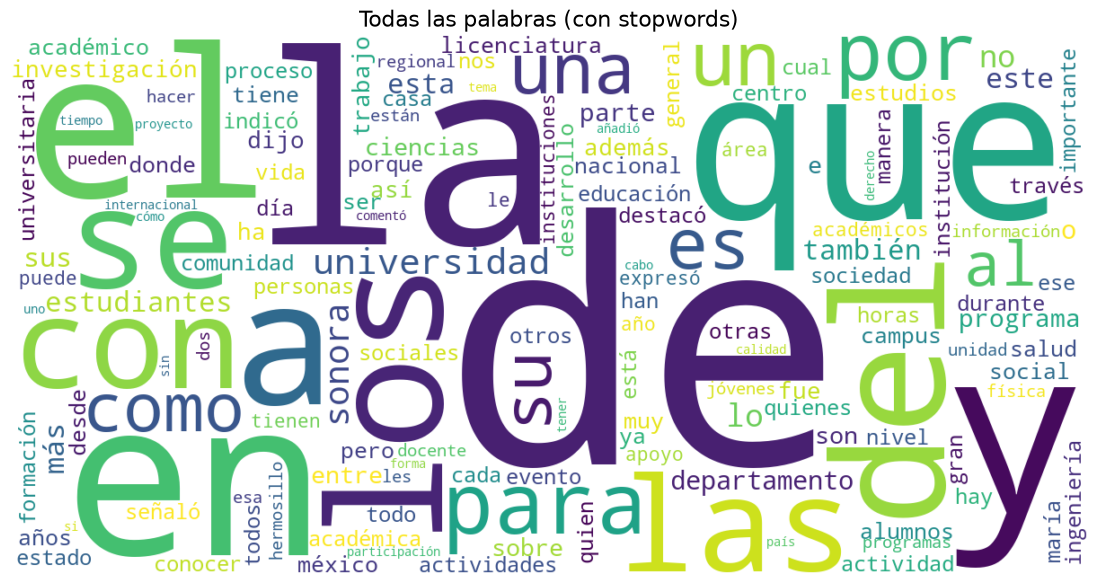

In [28]:
dibujar_nube(frecuencias, "Todas las palabras (con stopwords)")

### 5.3 Nube quitando stopwords

Las *stopwords* son palabras muy frecuentes que casi no aportan significado por sí solas
(artículos, preposiciones, conjunciones...). Usamos la lista en español de NLTK.

In [29]:
nltk.download("stopwords", quiet=True)
stopwords_es = set(stopwords.words("spanish"))

print("Stopwords en la lista de NLTK:", len(stopwords_es))
print(sorted(stopwords_es)[:40])

Stopwords en la lista de NLTK: 313
['a', 'al', 'algo', 'algunas', 'algunos', 'ante', 'antes', 'como', 'con', 'contra', 'cual', 'cuando', 'de', 'del', 'desde', 'donde', 'durante', 'e', 'el', 'ella', 'ellas', 'ellos', 'en', 'entre', 'era', 'erais', 'eran', 'eras', 'eres', 'es', 'esa', 'esas', 'ese', 'eso', 'esos', 'esta', 'estaba', 'estabais', 'estaban', 'estabas']


In [30]:
frecuencias_sin_stopwords = Counter()
for palabra, conteo in frecuencias.items():
    if palabra not in stopwords_es:
        frecuencias_sin_stopwords[palabra] = conteo

pd.DataFrame(frecuencias_sin_stopwords.most_common(20), columns=["palabra", "frecuencia"])

,palabra,frecuencia
0,universidad,42898
1,sonora,37537
2,estudiantes,24637
3,departamento,19510
4,parte,18503
5,programa,18314
6,ciencias,16335
7,así,14565
8,dijo,14316
9,investigación,14068


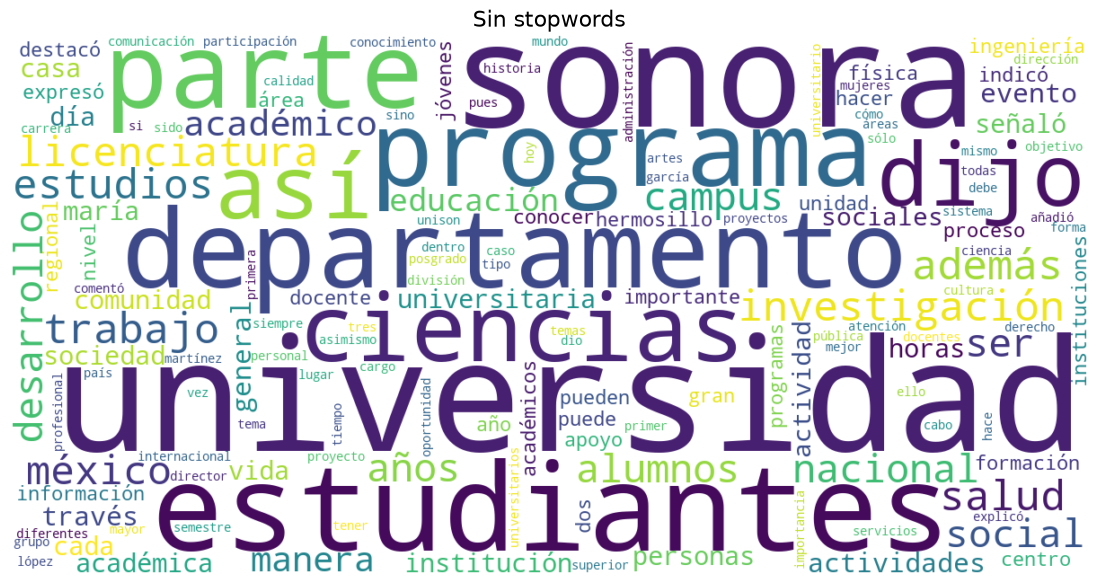

In [31]:
dibujar_nube(frecuencias_sin_stopwords, "Sin stopwords")

### 5.4 Comparación

In [32]:
palabras_stopwords = total_palabras - sum(frecuencias_sin_stopwords.values())

print(f"Las stopwords son solo {len(stopwords_es)} palabras distintas,")
print(f"pero ocupan el {palabras_stopwords / total_palabras:.0%} de todo el texto.")

Las stopwords son solo 313 palabras distintas,
pero ocupan el 47% de todo el texto.


In [33]:
comparacion = pd.DataFrame({
    "con stopwords": [palabra for palabra, conteo in frecuencias.most_common(15)],
    "sin stopwords": [palabra for palabra, conteo in frecuencias_sin_stopwords.most_common(15)],
})
comparacion.index = comparacion.index + 1
comparacion

,con stopwords,sin stopwords
1,de,universidad
2,la,sonora
3,y,estudiantes
4,en,departamento
5,que,parte
6,el,programa
7,a,ciencias
8,los,así
9,del,dijo
10,se,investigación


### Observaciones

- **Con stopwords** la nube solo muestra *de, la, y, en, que...* y no dice nada del contenido.
  Son apenas ~300 palabras distintas pero ocupan **casi la mitad de todo el texto**
  (ley de Zipf: pocas palabras concentran la mayor parte de las apariciones).
- **Sin stopwords** aparece el contenido, pero dominan tres tipos de palabras que tampoco cuentan una historia:
  - **Institucionales**, presentes en casi todas las notas: *universidad, sonora, departamento, programa, estudiantes*.
  - **Verbos de reporte**, propios del estilo periodístico: *dijo, señaló, indicó, destacó, expresó, añadió*.
  - **Conectores que la lista de NLTK no incluye**: *así, además, parte* (de "forma parte"), *través* (de "a través").
- **Conclusión:** una nube global describe el *género* (periodismo institucional), no los *temas*.
  Para contar una historia hay que **comparar** (entre años, meses o departamentos) y ampliar
  la lista de stopwords con palabras del dominio.

### 5.5 Una nube por mes

Hacemos la primera comparación: ¿de qué se habla en cada mes? Juntamos las noticias del mismo mes
de todos los años (todos los eneros, todos los febreros...) y contamos en **cuántas noticias** aparece cada palabra.

In [34]:
# Los nombres de los meses aparecen en las fechas ("el 15 de marzo") y llenarían cada nube con su propio mes
MESES_EN_TEXTO = {"enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
                  "agosto", "septiembre", "octubre", "noviembre", "diciembre"}

noticias_por_mes = noticias["mes"].value_counts()
noticias_con_palabra = {mes: Counter() for mes in range(1, 13)}   # mes -> palabra -> en cuántas noticias aparece

for texto, mes in zip(noticias["texto"], noticias["mes"]):
    palabras = set(tokenizar(texto))          # set: cada palabra cuenta una vez por noticia
    palabras = palabras - stopwords_es - MESES_EN_TEXTO
    noticias_con_palabra[mes].update(palabras)

for mes in range(1, 13):
    print(nombres_meses[mes - 1], [palabra for palabra, n in noticias_con_palabra[mes].most_common(8)])

Ene ['universidad', 'sonora', 'parte', 'estudiantes', 'departamento', 'programa', 'así', 'además']
Feb ['universidad', 'sonora', 'parte', 'departamento', 'estudiantes', 'así', 'además', 'dijo']
Mar ['universidad', 'sonora', 'parte', 'estudiantes', 'departamento', 'dijo', 'así', 'programa']
Abr ['universidad', 'sonora', 'estudiantes', 'parte', 'departamento', 'así', 'dijo', 'programa']
May ['universidad', 'sonora', 'parte', 'estudiantes', 'departamento', 'así', 'además', 'dijo']
Jun ['universidad', 'sonora', 'parte', 'departamento', 'estudiantes', 'así', 'dijo', 'además']
Jul ['universidad', 'sonora', 'departamento', 'parte', 'dijo', 'así', 'además', 'programa']
Ago ['universidad', 'sonora', 'estudiantes', 'parte', 'departamento', 'programa', 'así', 'además']
Sep ['universidad', 'sonora', 'parte', 'estudiantes', 'departamento', 'además', 'así', 'programa']
Oct ['universidad', 'sonora', 'estudiantes', 'parte', 'departamento', 'así', 'además', 'programa']
Nov ['universidad', 'sonora', 'es

Todos los meses empiezan igual: *universidad, sonora, estudiantes...*, las palabras del dominio que vimos en 5.3.
Con estas frecuencias las 12 nubes saldrían casi idénticas.

Para ver lo propio de cada mes **comparamos**: ¿en qué porcentaje de las noticias del mes aparece la palabra,
y en qué porcentaje de todas las noticias? Por ejemplo, si *navidad* aparece en el 4.7% de las notas de diciembre
y en el 0.5% del total, en diciembre se usa **unas 10 veces más** de lo normal. Una palabra como *universidad*,
que aparece igual todo el año, queda en 1 vez.

Además pedimos que la palabra aparezca en al menos 20 noticias del mes, para no premiar palabras raras
que salen en una o dos notas.

In [35]:
MINIMO_NOTICIAS_MES = 20
total_noticias = len(noticias)

noticias_con_palabra_total = Counter()
for conteo in noticias_con_palabra.values():
    noticias_con_palabra_total.update(conteo)


def palabras_del_mes(mes, n=40):
    """Las n palabras que más destacan en el mes: cuántas veces más se usan que en el total de noticias."""
    veces_mas = Counter()
    for palabra, n_noticias in noticias_con_palabra[mes].items():
        if n_noticias >= MINIMO_NOTICIAS_MES:
            porcentaje_mes = n_noticias / noticias_por_mes[mes]
            porcentaje_total = noticias_con_palabra_total[palabra] / total_noticias
            veces_mas[palabra] = porcentaje_mes / porcentaje_total
    return dict(veces_mas.most_common(n))


print("Las 5 palabras que más destacan en diciembre:")
for palabra, veces in palabras_del_mes(12, n=5).items():
    print(f"  {palabra}: {veces:.1f} veces más que en el total")

destacadas = pd.DataFrame({nombres_meses[mes - 1]: list(palabras_del_mes(mes, n=10)) for mes in range(1, 13)})
destacadas.index = destacadas.index + 1
destacadas

Las 5 palabras que más destacan en diciembre:
  decembrina: 11.6 veces más que en el total
  navideña: 11.5 veces más que en el total
  navideñas: 11.4 veces más que en el total
  navidad: 10.3 veces más que en el total
  navideño: 10.1 veces más que en el total


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
1,costumbrista,agrónomos,escritoras,graduantes,judo,delfín,monólogos,inducción,sismo,convisión,altares,decembrina
2,faot,parejas,féminas,pasante,preseas,corrimiento,monólogo,elegido,izamiento,estudiantina,catrinas,navideña
3,tirado,materna,primavera,graduación,homenajeados,listas,teros,ingreso,sismos,pedestre,procesión,navideñas
4,nutriólogo,noviazgo,paridad,graduados,pitic,verano,sola,reinscripciones,patrio,isi,xxviii,navidad
5,ordinarias,agropecuaria,trabajadoras,escolta,kilogramos,intensivo,temperaturas,cálida,juramento,tlatelolco,eliminación,navideño
6,barítono,amistad,feminicidio,certificados,homenajeado,solares,compañía,circulación,patria,frontispicio,muertos,decembrinas
7,reinscripciones,agronomía,femenina,cartas,universiada,pacífico,verano,tutores,simulacro,serenata,hispanoamericana,biofísica
8,reinscripción,admision,feminista,despedida,staus,cov,señal,formarse,evacuación,sobrevivientes,altar,regalos
9,nutriólogos,agropecuario,feminismo,unesco,admision,rendición,voz,competitivos,independencia,catrinas,coloquio,juguetes
10,álamos,bahía,conmemorativas,interdisciplinarias,reactivos,sars,calor,integrarse,cívica,mañanitas,mañanitas,emitida


Y las nubes: el tamaño de cada palabra indica cuántas veces más se usa en ese mes que en el total.

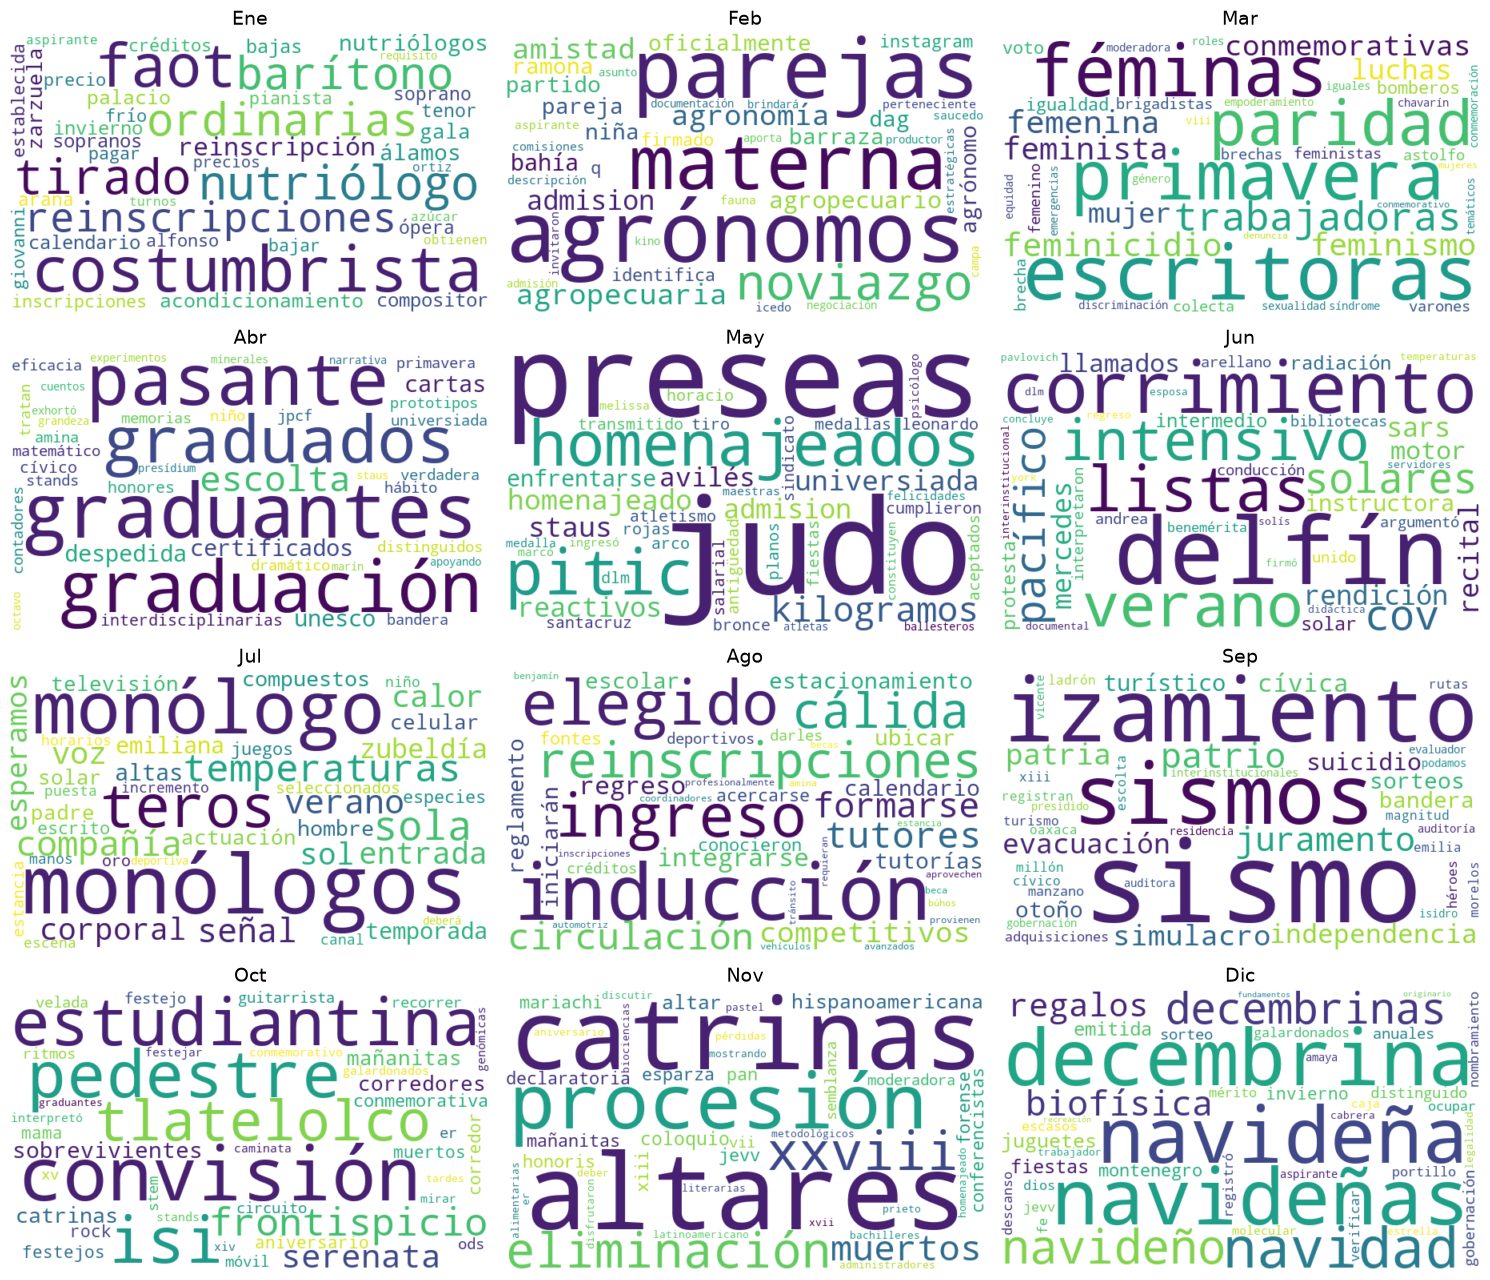

In [36]:
fig, ejes = plt.subplots(4, 3, figsize=(15, 13))

for mes, eje in zip(range(1, 13), ejes.flatten()):
    nube = WordCloud(width=600, height=350, background_color="white", random_state=42)
    nube.generate_from_frequencies(palabras_del_mes(mes))
    eje.imshow(nube, interpolation="bilinear")
    eje.set_title(nombres_meses[mes - 1], fontsize=14)
    eje.axis("off")

plt.tight_layout()
plt.show()

### Observaciones de las nubes por mes

- **Contar no basta, comparar sí:** con conteos simples todos los meses dicen lo mismo. Al comparar cada mes
  contra el total aparece el **calendario de la universidad**:
  - **Enero:** el Festival Alfonso Ortiz Tirado (*FAOT, Tirado, Álamos, barítono*: ópera y canto en Álamos),
    las *reinscripciones* y el Día del *Nutriólogo* (27 de enero).
  - **Febrero:** *parejas, noviazgo, amistad* (14 de febrero), los festejos de los *agrónomos* y el Día Internacional
    de la Lengua *Materna* (21 de febrero).
  - **Marzo:** el Día Internacional de la Mujer: *escritoras, féminas, paridad, trabajadoras, feminicidio, feminismo*.
  - **Abril:** el fin de la carrera: *graduantes, graduación*, entrega de *certificados de pasante*, ceremonias con *escolta*.
  - **Mayo:** deporte (*judo, preseas, Universiada*), *homenajeados* (homenaje a los docentes por antigüedad)
    y el examen de admisión (*admision, reactivos*).
  - **Junio:** el *verano* de investigación (*Programa Delfín, Pacífico*) y las listas de admitidos (*corrimiento de listas*).
  - **Julio:** casi no hay notas (vacaciones). Destaca el Festival de *Monólogos* "Teatro a una sola voz" (2015–2018);
    *teros* no es un tema, es la firma del reportero que lo cubría (Cruz Teros). Y el *calor*: *temperaturas*.
  - **Agosto:** el inicio de semestre: *inducción, ingreso, reinscripciones, tutores*.
  - **Septiembre:** las fiestas patrias (*izamiento, patria, juramento, independencia*), *sismo* y *simulacro*
    (sobre todo por los sismos de 2017) y la prevención del *suicidio*.
  - **Octubre:** el aniversario (*estudiantina, serenata, mañanitas, frontispicio*), el 2 de octubre (*Tlatelolco*),
    la lucha contra el cáncer de mama (*sobrevivientes*, la *carrera pedestre*) y congresos que se repiten
    cada octubre (*Convisión*, *ISI*).
  - **Noviembre:** el Día de Muertos (*altares, catrinas, procesión*) y el Día de la *Eliminación* de la Violencia
    contra la Mujer (25 de noviembre); también muchos *coloquios*.
  - **Diciembre:** *decembrina, navideña, navidad, regalos, juguetes* y la Escuela Nacional de *Biofísica* Molecular.
- **Lectura:** lo que distingue a cada mes son **eventos que se repiten cada año** (festivales, fechas conmemorativas,
  el calendario escolar), no noticias sueltas. Esto confirma el pico de octubre–noviembre de la sección 4.4.
- **Cuidado:** al juntar todos los años, un evento grande de un solo año puede colarse en su mes
  (*sismo* es casi todo de 2017; *sars* y *cov* aparecen en junio por 2020). Y siguen apareciendo firmas de reporteros
  dentro del texto (*teros*), que conviene limpiar antes de un análisis de temas.

## 6. Departamentos en las noticias

Las notas suelen nombrar al departamento académico de forma explícita: *"...del Departamento de Física"*.
Vamos a:

1. Extraer esos nombres con una expresión regular.
2. Limpiar las variantes de un mismo nombre.
3. Contar en cuántas noticias aparece cada departamento.
4. Ver cómo cambia su presencia año con año.

### 6.1 Extraer los nombres

Un nombre de departamento es una secuencia de palabras que empiezan con mayúscula y que puede
llevar en medio palabras cortas como *de, y, en, la* (p. ej. *Investigación y Posgrado en Alimentos*).

In [37]:
PALABRA_MAYUSCULA = r"[A-ZÁÉÍÓÚÑ][\w-]+"     # Física, Químico-Biológicas, ...
CONECTOR = r"(?:de|del|y|e|en|la)"            # palabras cortas permitidas dentro del nombre
NOMBRE = PALABRA_MAYUSCULA + r"(?:\s+(?:" + CONECTOR + r"\s+)*" + PALABRA_MAYUSCULA + r")*"

patron_departamento = re.compile(r"[Dd]epartamento de (" + NOMBRE + ")")

prueba = ("El Departamento de Letras y Lingüística de la Universidad de Sonora "
          "y el departamento de Física organizaron el evento.")
patron_departamento.findall(prueba)

['Letras y Lingüística de la Universidad de Sonora', 'Física']

El patrón encuentra los dos departamentos, pero a veces se lleva de más
(*"...de la Universidad de Sonora"*). Lo corregimos en el siguiente paso.

### 6.2 Limpiar las variantes

Al revisar los conteos aparecen tres tipos de variantes:
- **Sufijos** que dicen a qué universidad o unidad pertenece: *"Física de la Universidad de Sonora"*, *"... de la URS"*.
- **Guiones**: *"Químico-Biológicas"* vs. *"Químico Biológicas"*.
- **Abreviaturas o redacción distinta**: *"Psicom"*, *"Medicina"*, *"Ciencia del Deporte y Actividad Física"*.

Además, *"Física, Matemáticas e Ingeniería"* lleva una coma; lo resolvemos al contar (sección 6.3).

In [38]:
# Variantes que encontramos revisando los nombres más frecuentes -> nombre oficial
VARIANTES = {
    "Psicom": "Psicología y Ciencias de la Comunicación",
    "Psicología": "Psicología y Ciencias de la Comunicación",
    "Medicina": "Medicina y Ciencias de la Salud",
    "Ciencias del Deporte y la Actividad Física": "Ciencias del Deporte y de la Actividad Física",
    "Ciencia del Deporte y Actividad Física": "Ciencias del Deporte y de la Actividad Física",
    "Ciencia del Deporte y la Actividad Física": "Ciencias del Deporte y de la Actividad Física",
    "Ciencias del Deporte y Actividad Física": "Ciencias del Deporte y de la Actividad Física",
    "Psicología y Comunicación": "Psicología y Ciencias de la Comunicación",
    "Ciencias Económicas Administrativas": "Ciencias Económico Administrativas",
    "Ciencias Económicas y Administrativas": "Ciencias Económico Administrativas",
    "Ciencias Económico Administrativo": "Ciencias Económico Administrativas",
    "Ingeniería Química": "Ingeniería Química y Metalurgia",
    "Ingeniería Química y Metalúrgica": "Ingeniería Química y Metalurgia",
    "Ingeniería Industrial y de Sistemas": "Ingeniería Industrial",
    "Ingeniería Civil": "Ingeniería Civil y Minas",
    "Polímeros y Materiales": "Investigación en Polímeros y Materiales",
    "Químico Biológicas y Agropecuarias": "Ciencias Químico Biológicas y Agropecuarias",
    "Sociología y Administración": "Sociología y Administración Pública",
    "Historia": "Historia y Antropología",
    "Agricultura": "Agricultura y Ganadería",
    "Arquitectura": "Arquitectura y Diseño",
    "Letras": "Letras y Lingüística",
    "Lenguas": "Lenguas Extranjeras",
    "Investigación y Posgrado": "Investigación y Posgrado en Alimentos",
}


def limpiar_departamento(nombre):
    nombre = nombre.replace("-", " ")
    # Quitamos lo que indica a qué universidad o unidad regional pertenece
    nombre = re.sub(r" (de|en) la (Universidad|Unison|Unidad Regional|URC|URN|URS|Alma Mater|Máxima Casa).*$",
                    "", nombre, flags=re.IGNORECASE)
    return VARIANTES.get(nombre, nombre)


print(limpiar_departamento("Letras y Lingüística de la Universidad de Sonora"))
print(limpiar_departamento("Ciencias Químico-Biológicas"))
print(limpiar_departamento("Psicom"))

Letras y Lingüística
Ciencias Químico Biológicas
Psicología y Ciencias de la Comunicación


### 6.3 ¿En cuántas noticias aparece cada departamento?

Contamos **noticias**, no menciones: si una nota nombra cinco veces al mismo departamento, cuenta una sola vez.
Armamos una tabla con una fila por cada par (noticia, departamento).

In [39]:
filas = []
for _, noticia in noticias.iterrows():
    # "Física, Matemáticas e Ingeniería" (campus Caborca y Navojoa) es el único nombre con coma.
    # Sin este ajuste el patrón se detiene en la coma y lo contaría como "Física" (Hermosillo).
    texto = noticia["texto"].replace("Física, Matemáticas", "Física Matemáticas")
    nombres = patron_departamento.findall(texto)
    departamentos = set(limpiar_departamento(nombre) for nombre in nombres)
    for departamento in departamentos:
        filas.append({"id": noticia["id"], "anio": noticia["anio"], "departamento": departamento})

menciones = pd.DataFrame(filas)

print("Noticias que mencionan al menos un departamento:", menciones["id"].nunique(), "de", len(noticias))
menciones.head()

Noticias que mencionan al menos un departamento: 10212 de 19813


,id,anio,departamento
0,18387,2015,Derecho
1,18388,2015,Geología
2,18390,2015,Economía
3,18391,2015,Lenguas Extranjeras
4,18392,2015,Historia y Antropología


In [40]:
conteo = menciones["departamento"].value_counts()
print("Nombres distintos encontrados:", len(conteo))
conteo.head(40)

Nombres distintos encontrados: 973


departamento
Bellas Artes                                     689
Ciencias Químico Biológicas                      602
Economía                                         593
Derecho                                          587
Psicología y Ciencias de la Comunicación         561
Ciencias Sociales                                551
Medicina y Ciencias de la Salud                  452
Física                                           434
Investigación y Posgrado en Alimentos            433
Contabilidad                                     418
Letras y Lingüística                             416
Ciencias Económico Administrativas               399
Sociología y Administración Pública              390
Matemáticas                                      372
Agricultura y Ganadería                          352
Ciencias Químico Biológicas y Agropecuarias      324
Ingeniería Industrial                            317
Enfermería                                       283
Investigación en Física          

Hay muchos nombres que aparecen muy pocas veces (errores de redacción, oficinas administrativas,
departamentos de otras instituciones). Nos quedamos con los que aparecen en al menos 50 noticias.

In [41]:
MINIMO_NOTICIAS = 50
principales = conteo[conteo >= MINIMO_NOTICIAS]

print("Departamentos con al menos", MINIMO_NOTICIAS, "noticias:", len(principales))
principales

Departamentos con al menos 50 noticias: 33


departamento
Bellas Artes                                     689
Ciencias Químico Biológicas                      602
Economía                                         593
Derecho                                          587
Psicología y Ciencias de la Comunicación         561
Ciencias Sociales                                551
Medicina y Ciencias de la Salud                  452
Física                                           434
Investigación y Posgrado en Alimentos            433
Contabilidad                                     418
Letras y Lingüística                             416
Ciencias Económico Administrativas               399
Sociología y Administración Pública              390
Matemáticas                                      372
Agricultura y Ganadería                          352
Ciencias Químico Biológicas y Agropecuarias      324
Ingeniería Industrial                            317
Enfermería                                       283
Investigación en Física          

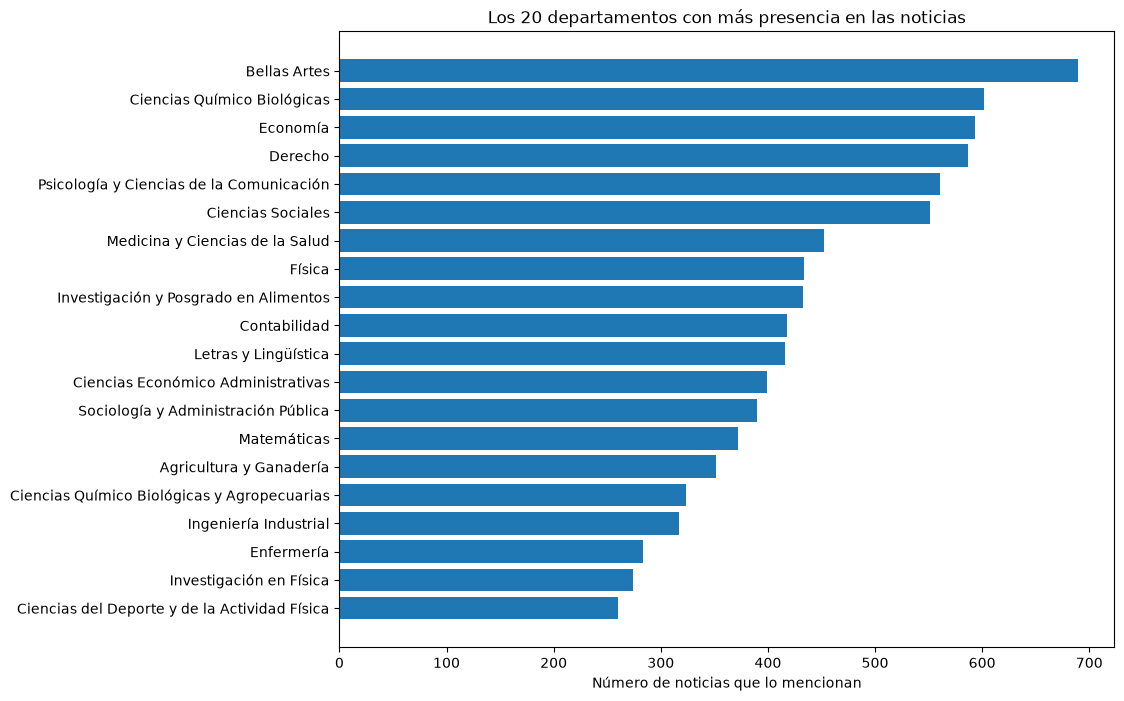

In [42]:
top = principales.head(20).sort_values()

plt.figure(figsize=(10, 8))
plt.barh(top.index, top.values)
plt.title("Los 20 departamentos con más presencia en las noticias")
plt.xlabel("Número de noticias que lo mencionan")
plt.show()

*Ojo:* algunos nombres existen en más de una unidad regional (p. ej. *Ciencias Sociales* está en
la Unidad Regional Norte y en la Sur). Al quitar el sufijo de la unidad quedan juntos.

### 6.4 Evolución por año

No todos los años se publicó la misma cantidad de noticias, así que en lugar de contar noticias
calculamos el **porcentaje de las noticias de cada año** que mencionan al departamento.

Primero, como contexto: ¿qué porcentaje de las noticias de cada año menciona algún departamento?

In [43]:
noticias_por_anio = noticias["anio"].value_counts().sort_index()
noticias_con_departamento = menciones.groupby("anio")["id"].nunique()

(noticias_con_departamento / noticias_por_anio * 100).round(1)

anio
2015    48.8
2016    49.9
2017    49.3
2018    46.9
2019    49.3
2020    55.4
2021    51.9
2022    55.2
2023    51.6
2024    54.4
2025    55.6
2026    60.6
dtype: float64

In [44]:
menciones_principales = menciones[menciones["departamento"].isin(principales.index)]
noticias_por_departamento = pd.crosstab(menciones_principales["departamento"], menciones_principales["anio"])

porcentaje = noticias_por_departamento / noticias_por_anio * 100
porcentaje = porcentaje.loc[principales.index]  # ordenados de mayor a menor presencia total

porcentaje.round(1).style.background_gradient(cmap="Blues", axis=None).format("{:.1f}")

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
departamento,,,,,,,,,,,,
Bellas Artes,3.4,3.7,2.9,2.2,2.1,3.6,3.7,4.2,4.4,3.9,4.6,4.5
Ciencias Químico Biológicas,2.9,3.3,3.1,2.4,2.6,3.7,1.8,2.7,3.3,3.6,3.4,4.6
Economía,3.6,3.3,4.3,3.4,3.3,4.0,2.1,2.2,1.8,2.3,2.4,1.8
Derecho,3.4,3.4,3.1,2.1,2.8,3.5,4.5,4.0,2.4,2.1,2.3,1.6
Psicología y Ciencias de la Comunicación,2.1,2.9,2.3,1.8,2.5,3.1,3.5,4.5,3.0,3.2,2.6,3.9
Ciencias Sociales,2.1,2.1,1.9,2.7,2.6,4.0,3.3,2.0,2.8,3.9,3.4,5.5
Medicina y Ciencias de la Salud,2.1,2.4,1.9,2.2,2.2,1.0,0.5,2.6,3.6,3.0,3.3,2.1
Física,2.9,2.1,2.9,1.9,1.5,1.9,1.7,2.0,1.9,1.9,2.3,3.0
Investigación y Posgrado en Alimentos,2.1,2.4,2.0,2.2,2.5,2.2,2.1,2.0,2.0,2.2,2.4,2.0


Los seis departamentos con más presencia, año por año:

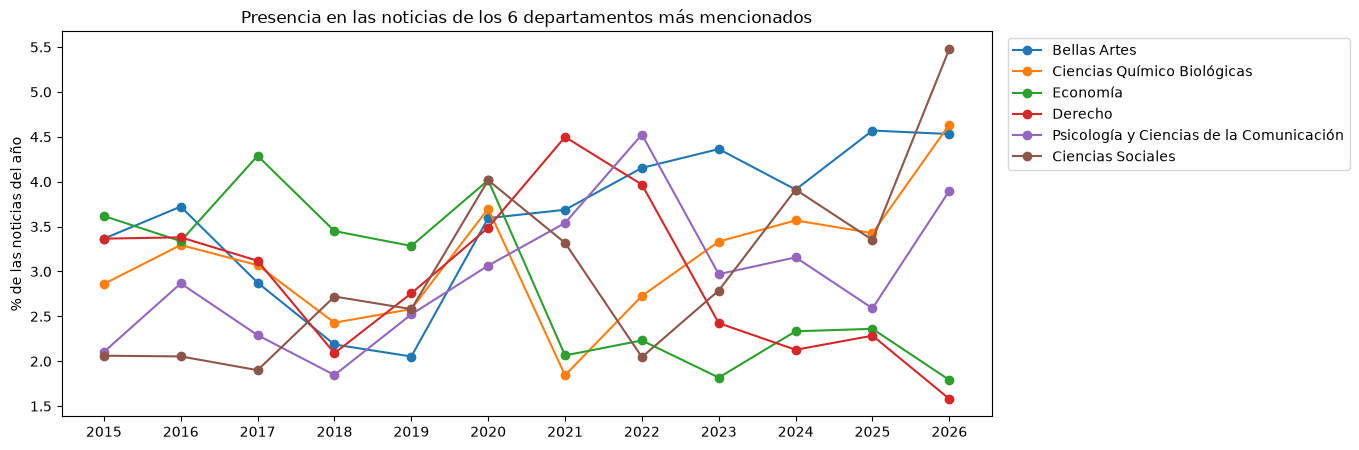

In [45]:
plt.figure(figsize=(12, 5))
for departamento in principales.index[:6]:
    plt.plot(porcentaje.columns, porcentaje.loc[departamento], marker="o", label=departamento)

plt.title("Presencia en las noticias de los 6 departamentos más mencionados")
plt.ylabel("% de las noticias del año")
plt.xticks(porcentaje.columns)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")  # leyenda fuera de la gráfica
plt.show()

### 6.5 ¿Quién ganó y quién perdió presencia?

Comparamos el promedio de los tres primeros años contra el de los tres últimos.

In [46]:
anios = list(porcentaje.columns)
primeros = anios[:3]
ultimos = anios[-3:]
etiqueta_inicio = f"{primeros[0]}–{primeros[-1]}"
etiqueta_final = f"{ultimos[0]}–{ultimos[-1]}"

cambio = pd.DataFrame({
    etiqueta_inicio: porcentaje[primeros].mean(axis=1),
    etiqueta_final: porcentaje[ultimos].mean(axis=1),
})
cambio["diferencia"] = cambio[etiqueta_final] - cambio[etiqueta_inicio]

cambio.sort_values("diferencia").round(2)

,2015–2017,2024–2026,diferencia
departamento,,,
Economía,3.75,2.16,-1.59
Derecho,3.29,2.00,-1.29
Sociología y Administración Pública,2.14,1.04,-1.10
Contabilidad,2.56,1.87,-0.70
Trabajo Social,1.17,0.76,-0.40
Física,2.64,2.39,-0.26
Ingeniería Civil y Minas,1.15,1.12,-0.03
Investigación y Posgrado en Alimentos,2.18,2.19,0.00
Ingeniería Industrial,1.56,1.63,0.07


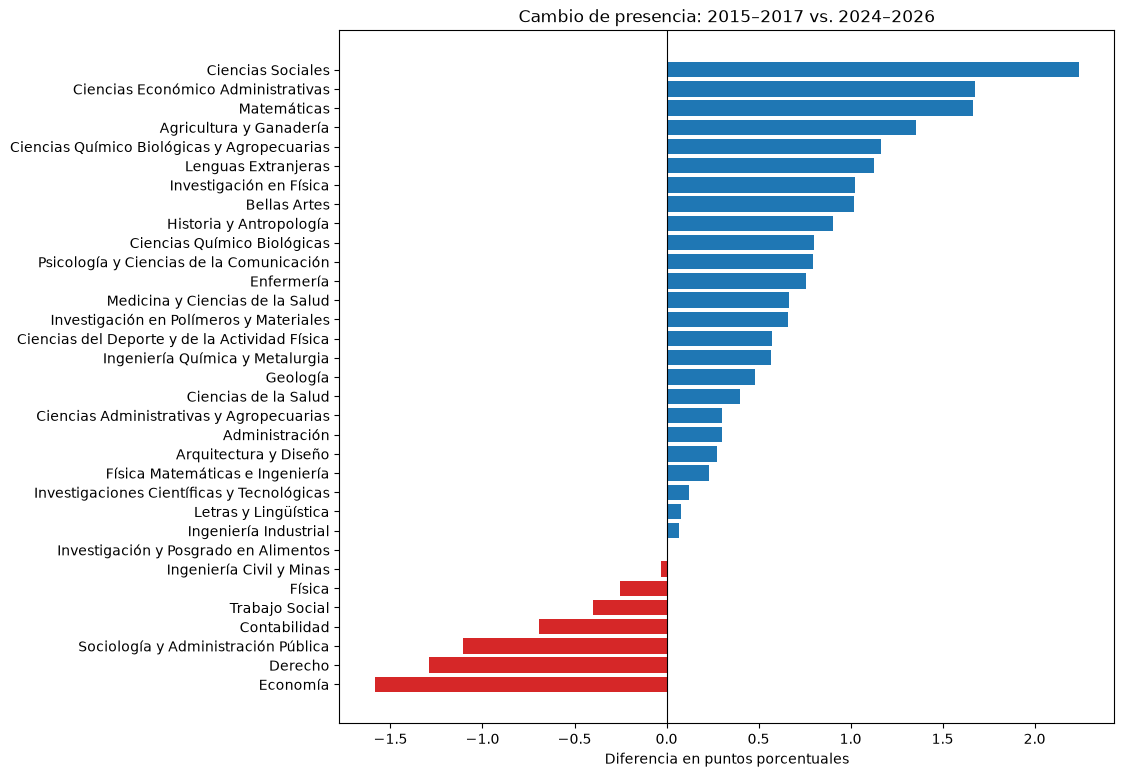

In [47]:
cambio_ordenado = cambio["diferencia"].sort_values()
colores = ["tab:red" if valor < 0 else "tab:blue" for valor in cambio_ordenado]

plt.figure(figsize=(10, 9))
plt.barh(cambio_ordenado.index, cambio_ordenado.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Cambio de presencia: {etiqueta_inicio} vs. {etiqueta_final}")
plt.xlabel("Diferencia en puntos porcentuales")
plt.show()

### 6.6 ¿Ganar porcentaje es ganar noticias?

Usamos porcentajes porque el número de noticias cambia mucho entre años. Pero tiene una trampa:
si el total de noticias baja un tercio, un departamento que **se mantiene** en el mismo número de notas
parece que **gana** presencia. Revisamos los números absolutos: noticias por año en promedio,
usando solo años completos (2026 queda fuera).

In [48]:
anios_cerrados = anios[:-1]          # sin el último año, que está incompleto
inicio = anios_cerrados[:3]
final = anios_cerrados[-3:]
columna_inicio = f"{inicio[0]}–{inicio[-1]}"
columna_final = f"{final[0]}–{final[-1]}"

absolutos = pd.DataFrame({
    columna_inicio: noticias_por_departamento[inicio].mean(axis=1),
    columna_final: noticias_por_departamento[final].mean(axis=1),
})
absolutos["cambio %"] = (absolutos[columna_final] / absolutos[columna_inicio] - 1) * 100

cambio_total = (noticias_por_anio[final].mean() / noticias_por_anio[inicio].mean() - 1) * 100
print(f"Noticias por año: {noticias_por_anio[inicio].mean():.0f} -> "
      f"{noticias_por_anio[final].mean():.0f} ({cambio_total:.0f}%)")

absolutos.sort_values("cambio %").round(1)

Noticias por año: 2255 -> 1473 (-35%)


,2015–2017,2023–2025,cambio %
departamento,,,
Economía,84.0,31.7,-62.3
Contabilidad,57.3,21.7,-62.2
Física Matemáticas e Ingeniería,29.0,12.0,-58.6
Trabajo Social,25.7,11.3,-55.8
Derecho,74.3,33.7,-54.7
Física,59.3,29.7,-50.0
Sociología y Administración Pública,48.0,24.3,-49.3
Ingeniería Civil y Minas,25.7,13.3,-48.1
Ingeniería Industrial,35.3,21.0,-40.6


La línea gris marca cuánto bajó el total de noticias. Los departamentos a su derecha ganaron peso relativo.

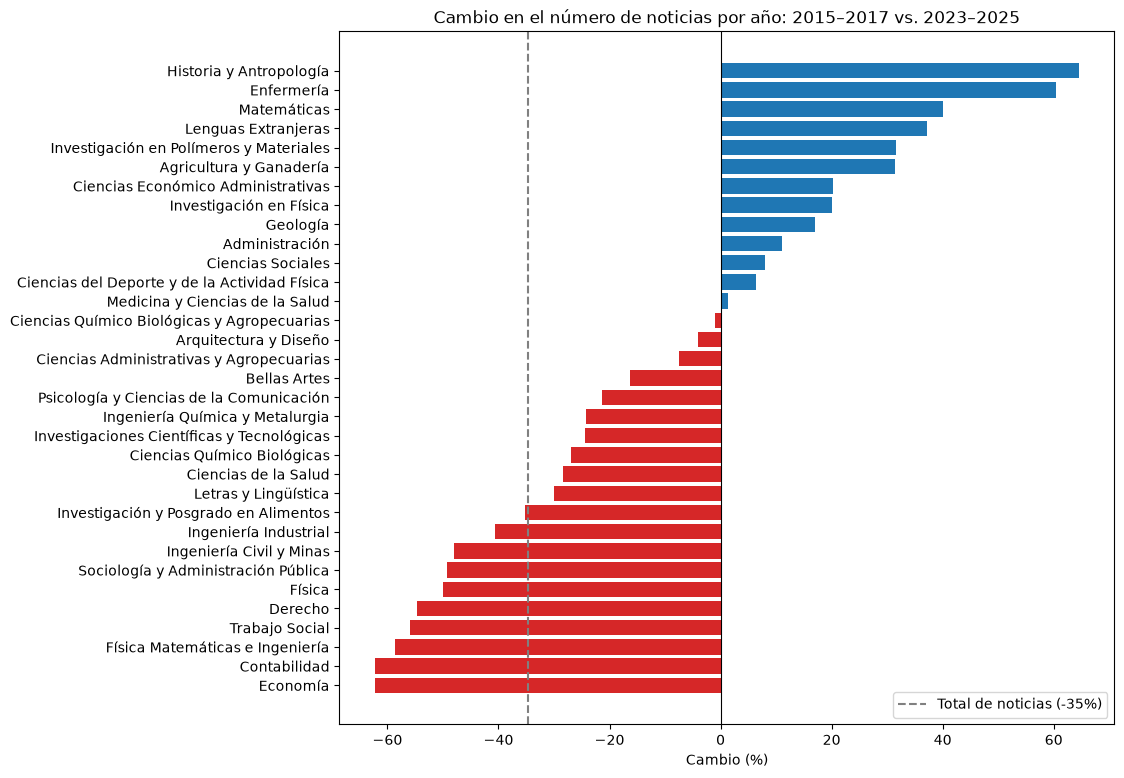

In [49]:
cambio_absoluto = absolutos["cambio %"].sort_values()
colores = ["tab:red" if valor < 0 else "tab:blue" for valor in cambio_absoluto]

plt.figure(figsize=(10, 9))
plt.barh(cambio_absoluto.index, cambio_absoluto.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(cambio_total, color="gray", linestyle="--", label=f"Total de noticias ({cambio_total:.0f}%)")
plt.title(f"Cambio en el número de noticias por año: {columna_inicio} vs. {columna_final}")
plt.xlabel("Cambio (%)")
plt.legend()
plt.show()

### 6.7 ¿Pierde presencia o solo cambia cómo se le nombra?

Una nota puede hablar de la carrera sin nombrar al departamento (*"estudiantes de la Licenciatura en Derecho"*).
Comparamos las dos formas de nombrarlos para Derecho y Economía, dos de los que más pierden.

Para esto escribimos una función que reutilizaremos en las secciones 7 y 8: el porcentaje de las noticias
de cada año cuyo texto contiene una expresión.

In [50]:
def porcentaje_por_anio(patron):
    """Porcentaje de las noticias de cada año que contienen el patrón (sin distinguir mayúsculas)."""
    contiene = noticias["texto"].str.contains(patron, case=False)
    return (contiene.groupby(noticias["anio"]).mean() * 100).round(1)


formas_de_nombrar = pd.DataFrame({
    "Departamento de Derecho": porcentaje_por_anio("departamento de derecho"),
    "Licenciatura en Derecho": porcentaje_por_anio("licenciatura en derecho"),
    "Departamento de Economía": porcentaje_por_anio("departamento de economía"),
    "Licenciatura en Economía": porcentaje_por_anio("licenciatura en economía"),
})
formas_de_nombrar.T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Departamento de Derecho,3.5,3.5,3.2,2.2,2.8,3.5,4.6,4.1,2.4,2.1,2.3,1.6
Licenciatura en Derecho,2.9,2.0,2.2,2.2,3.2,2.5,2.1,2.7,3.3,2.5,3.7,3.5
Departamento de Economía,3.7,3.3,4.3,3.5,3.5,4.3,2.1,2.4,1.9,2.4,2.4,1.8
Licenciatura en Economía,0.4,0.3,0.7,0.4,0.4,0.4,0.1,0.2,0.2,0.3,0.3,0.1


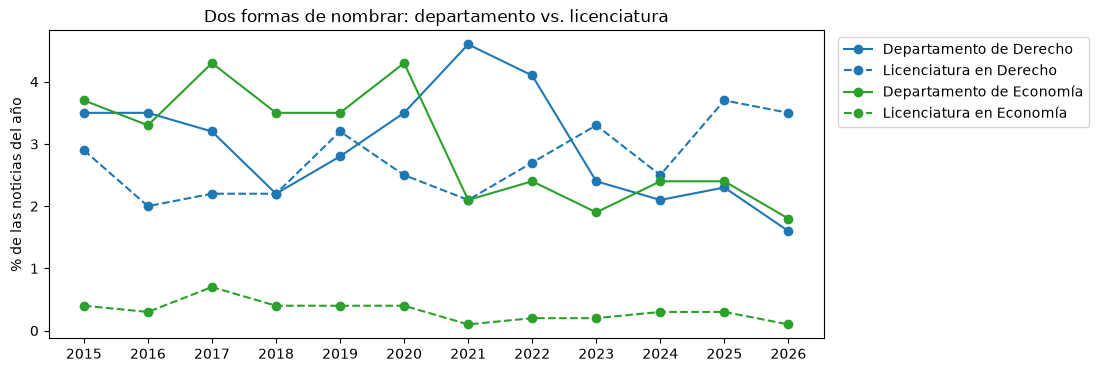

In [51]:
colores = {"Derecho": "tab:blue", "Economía": "tab:green"}   # un color por departamento

plt.figure(figsize=(10, 4))
for columna in formas_de_nombrar.columns:
    estilo = "-" if columna.startswith("Departamento") else "--"   # línea punteada = licenciatura
    color = colores[columna.split()[-1]]                            # última palabra: Derecho o Economía
    plt.plot(formas_de_nombrar.index, formas_de_nombrar[columna], estilo, marker="o", color=color, label=columna)

plt.title("Dos formas de nombrar: departamento vs. licenciatura")
plt.ylabel("% de las noticias del año")
plt.xticks(formas_de_nombrar.index)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

### Observaciones

- **La mitad de las noticias** (~10,200 de ~19,800) nombra al menos un departamento, y esa proporción
  **crece con el tiempo**: ~49% en 2015–2019, ~55% en 2020–2025 y ~61% en 2026.
  Parte de ese aumento se explica porque las notas dejaron de nombrar a las *Divisiones* (ver sección 7).
- **Los más presentes en todo el periodo:** Bellas Artes (~690 noticias), Ciencias Químico Biológicas,
  Economía, Derecho, Psicología y Ciencias de la Comunicación y Ciencias Sociales (~550–600 cada uno).
- **En porcentaje (6.5)**, los que más ganan son departamentos de los **campus regionales**
  (Caborca, Navojoa, Nogales, Santa Ana): *Ciencias Sociales* (de ~2.0% a ~4.3% de las noticias del año),
  *Ciencias Económico Administrativas* y *Ciencias Químico Biológicas y Agropecuarias*.
  Lo verificamos: casi el 100% de sus noticias menciona algún campus regional.
- **En números absolutos (6.6)** la imagen cambia: el total de noticias por año baja **35%** (de ~2,250 a ~1,470).
  - Los tres regionales que "ganaban" en porcentaje en realidad **se mantienen**: Ciencias Sociales +8%,
    Ciencias Económico Administrativas +20%, Ciencias Químico Biológicas y Agropecuarias −1%.
    No todos los regionales resisten: *Física, Matemáticas e Ingeniería* (Caborca y Navojoa) pierde 59%.
  - Los que **pierden la mitad o más** de sus notas son, sobre todo, de ciencias sociales y económico-administrativas
    de Hermosillo: Economía (−62%), Contabilidad (−62%), Trabajo Social (−56%), Derecho (−55%) y
    Sociología y Administración Pública (−49%). También Física (−50%) y las ingenierías Civil (−48%) e Industrial (−41%).
  - Los que **crecen de verdad** son de humanidades, salud y algunas ciencias: Historia y Antropología (+65%),
    Enfermería (+60%), Matemáticas (+40%), Lenguas Extranjeras (+37%), Agricultura y Ganadería (+31%).
  - Bellas Artes gana un punto porcentual, pero en realidad tiene 16% menos notas: solo bajó menos que el total.
- **Nombres (6.7):** la caída de Derecho es sobre todo de **nombre**: *Departamento de Derecho* baja de ~3.5% a ~2%,
  pero *Licenciatura en Derecho* sube de ~2–3% a ~3.5% (la carrera también se imparte en los campus regionales).
  En Economía bajan las dos formas, así que su pérdida sí es real.
- **Posible historia:** *en una sala de prensa que publica un tercio menos, economía y ciencias sociales de Hermosillo
  pierden más de la mitad de su cobertura, mientras humanidades, salud y tres departamentos regionales conservan
  o ganan espacio.*

**Limitaciones:**
- Los nombres compartidos por varias unidades regionales (p. ej. *Ciencias Sociales*) se cuentan juntos.
- No se capturan los plurales (*"los departamentos de Física y Matemáticas"*) ni las siglas sueltas (*DIFUS, DIPA*).
- Los valores de un solo año son ruidosos (decenas de notas por departamento); por eso comparamos promedios de tres años.
- 2026 está incompleto (hasta octubre): sirve para porcentajes, pero no para números absolutos.

## 7. Cambios de vocabulario en el tiempo

La nube de palabras global (sección 5) mezcla todos los años. Una forma sencilla de ver cambios es seguir
algunas expresiones y calcular qué porcentaje de las noticias de cada año las usa
(con la función `porcentaje_por_anio` de la sección 6.7).

### 7.1 La pandemia

In [52]:
pandemia = pd.DataFrame({
    "covid / pandemia": porcentaje_por_anio("covid|pandemia|coronavirus"),
    "virtual / en línea": porcentaje_por_anio("virtual|en línea|videoconferencia|zoom"),
})
pandemia.T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
covid / pandemia,0.2,0.0,0.1,0.0,0.1,29.8,34.9,21.7,9.8,4.5,3.8,1.8
virtual / en línea,4.1,3.3,4.6,4.1,5.8,40.9,49.9,22.4,11.0,9.5,7.8,11.6


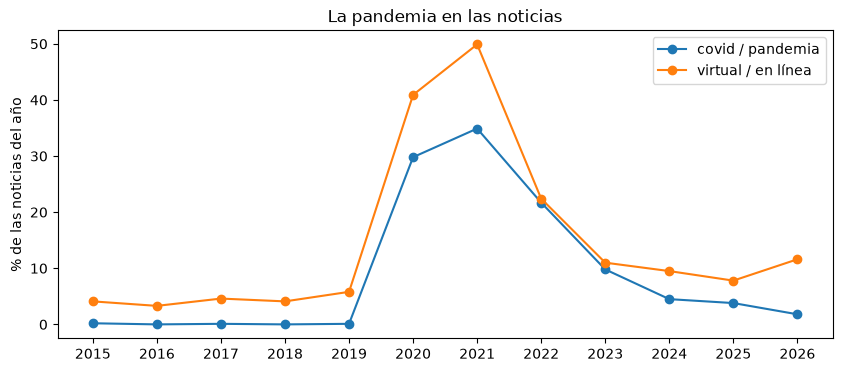

In [53]:
plt.figure(figsize=(10, 4))
for columna in pandemia.columns:
    plt.plot(pandemia.index, pandemia[columna], marker="o", label=columna)

plt.title("La pandemia en las noticias")
plt.ylabel("% de las noticias del año")
plt.xticks(pandemia.index)
plt.legend()
plt.show()

### 7.2 La estructura de la universidad

Al revisar los departamentos notamos que las notas recientes ya no hablan de *Unidades Regionales*
ni de *Divisiones*. Seguimos esas expresiones junto con *campus* y dos órganos de gobierno:
la *Junta Universitaria* y el *Colegio Universitario*.

In [54]:
PATRON_DIVISION = "división de ciencias|división de ingeniería|división de humanidades"

estructura = pd.DataFrame({
    "Unidad Regional": porcentaje_por_anio(r"unidad regional|\bur[cns]\b"),   # URC, URN, URS
    "División de ...": porcentaje_por_anio(PATRON_DIVISION),
    "campus": porcentaje_por_anio(r"\bcampus\b"),
    "Junta Universitaria": porcentaje_por_anio("junta universitaria"),
    "Colegio Universitario": porcentaje_por_anio("colegio universitario"),
})
estructura.T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Unidad Regional,20.7,18.7,20.7,27.8,24.0,25.5,22.3,20.6,6.2,0.3,0.2,0.2
División de ...,19.8,19.5,18.1,20.0,20.4,20.2,18.6,18.8,5.0,0.9,0.2,0.1
campus,26.8,27.4,23.8,25.8,27.1,29.4,25.1,27.8,37.2,40.5,45.6,47.3
Junta Universitaria,0.6,1.5,2.2,0.8,1.8,2.1,3.2,1.1,0.2,0.0,0.2,0.0
Colegio Universitario,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,1.5,0.3,1.7,0.4


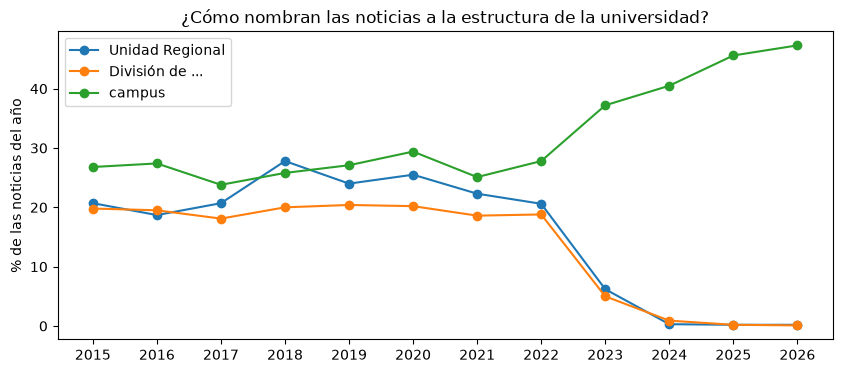

In [55]:
plt.figure(figsize=(10, 4))
for columna in ["Unidad Regional", "División de ...", "campus"]:
    plt.plot(estructura.index, estructura[columna], marker="o", label=columna)

plt.title("¿Cómo nombran las noticias a la estructura de la universidad?")
plt.ylabel("% de las noticias del año")
plt.xticks(estructura.index)
plt.legend()
plt.show()

¿Explica esto que crezcan las menciones de departamentos (sección 6.4)? Si antes algunas notas nombraban
solo a la División y ahora nombran al departamento, la suma de las dos debería mantenerse estable.

In [56]:
tiene_departamento = noticias["id"].isin(menciones["id"])
tiene_division = noticias["texto"].str.contains(PATRON_DIVISION, case=False)

departamento_o_division = pd.DataFrame({
    "departamento": tiene_departamento,
    "división": tiene_division,
    "departamento o división": tiene_departamento | tiene_division,
}).groupby(noticias["anio"]).mean() * 100

departamento_o_division.round(1).T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
departamento,48.8,49.9,49.3,46.9,49.3,55.4,51.9,55.2,51.6,54.4,55.6,60.6
división,19.8,19.5,18.1,20.0,20.4,20.2,18.6,18.8,5.0,0.9,0.2,0.1
departamento o división,56.1,56.1,54.8,53.8,56.4,60.8,57.9,60.7,53.6,54.6,55.7,60.7


### Observaciones

- **La pandemia se ve en el texto:** *covid/pandemia* no aparece antes de 2020 y sale en ~30% de las notas
  de 2020 y ~35% de 2021; hoy está en ~2%. Las palabras de formato a distancia (*virtual, en línea, zoom*) pasan
  de ~4% a **50% en 2021**, y se quedan en ~8–12%: el doble que antes de la pandemia.
  Esto ayuda a explicar 2020: menos notas, más largas y centradas en actividades en línea.
- **La universidad cambió su estructura en 2023 y el lenguaje lo registra:** *Unidad Regional* y *División*
  aparecían en ~20% de las notas cada una hasta 2022; caen a ~5–6% en 2023 y desaparecen desde 2024.
  Al mismo tiempo *campus* sube de ~27% a ~47%, la *Junta Universitaria* deja de mencionarse y aparece
  el *Colegio Universitario*. Parece un cambio en la organización de la universidad
  (conviene confirmarlo con una fuente oficial, p. ej. la ley orgánica).
- **Esto explica el aumento de departamentos (6.4):** las notas que nombran *un departamento o una División*
  se mantienen en ~54–61% todos los años. Lo que creció hasta 2025 fue la parte de departamentos, porque
  las notas que antes nombraban solo a la División ahora nombran al departamento.
- **Consecuencia para el análisis por campus:** como *Unidad Regional* dejó de usarse, hay que contar por
  nombre de ciudad (*Caborca, Navojoa, Nogales, Santa Ana, Cajeme, Hermosillo*), no por unidad.
- **Lección de método:** seguir unas cuantas expresiones por año descubre cambios que la nube global esconde.
  El siguiente paso es encontrarlos sin elegir las palabras a mano: TF-IDF por año (sección 8).

## 8. Palabras características de cada año (TF-IDF)

En la sección 7 elegimos a mano qué palabras seguir. Ahora queremos que los datos nos digan
qué palabras distinguen a cada año. Para eso usamos **TF-IDF**:

- **TF** (*term frequency*): qué tan frecuente es la palabra **dentro** de un documento.
- **IDF** (*inverse document frequency*): qué tan **rara** es la palabra entre todos los documentos.
- **TF-IDF = TF × IDF**: premia las palabras frecuentes en un documento y raras en los demás.

Aquí cada **documento es un año**: juntamos todas las noticias del año. Las fórmulas, con 12 años:

- TF(palabra, año) = veces que aparece la palabra en el año / total de palabras del año
- IDF(palabra) = log(12 / número de años en que aparece la palabra)

### 8.1 Contar las palabras de cada año

Contamos dos cosas por año: cuántas veces aparece cada palabra (para el TF) y en cuántas noticias aparece
(para filtrar más adelante las palabras que salen en muy pocas notas).

In [57]:
def contar_palabras_por_anio(textos):
    """Para cada año: cuántas veces aparece cada palabra y en cuántas noticias aparece."""
    veces = {}
    en_noticias = {}
    for anio, textos_del_anio in textos.groupby(noticias["anio"]):
        veces[anio] = Counter()
        en_noticias[anio] = Counter()
        for texto in textos_del_anio:
            palabras = [palabra for palabra in tokenizar(texto) if palabra not in stopwords_es]
            veces[anio].update(palabras)
            en_noticias[anio].update(set(palabras))   # set: cada palabra cuenta una vez por noticia
    return veces, en_noticias


veces_por_anio, en_noticias_por_anio = contar_palabras_por_anio(noticias["texto"])

print("Palabras (sin stopwords) por año:")
pd.Series({anio: sum(conteo.values()) for anio, conteo in veces_por_anio.items()})

Palabras (sin stopwords) por año:


2015    486636
2016    484437
2017    430127
2018    446327
2019    422614
2020    288767
2021    451135
2022    503042
2023    454894
2024    375724
2025    330011
2026    232052
dtype: int64

### 8.2 IDF: ¿en cuántos años aparece la palabra?

In [58]:
def calcular_idf(veces_por_anio):
    """IDF de cada palabra: log(número de años / número de años en que aparece)."""
    n_anios = len(veces_por_anio)
    anios_con_palabra = Counter()
    for conteo in veces_por_anio.values():
        anios_con_palabra.update(conteo.keys())   # cada año suma 1 a cada palabra que contiene
    return {palabra: math.log(n_anios / n) for palabra, n in anios_con_palabra.items()}


idf = calcular_idf(veces_por_anio)

ejemplos = ["universidad", "estudiantes", "virtual", "pandemia", "covid", "litio", "conahcyt", "secihti"]
pd.DataFrame({
    "años en que aparece": [sum(1 for conteo in veces_por_anio.values() if palabra in conteo) for palabra in ejemplos],
    "IDF": [round(idf[palabra], 2) for palabra in ejemplos],
}, index=ejemplos)

,años en que aparece,IDF
universidad,12,0.00
estudiantes,12,0.00
virtual,12,0.00
pandemia,12,0.00
covid,7,0.54
litio,7,0.54
conahcyt,4,1.10
secihti,2,1.79


Las palabras que aparecen los 12 años (*universidad, estudiantes*) tienen IDF = log(12/12) = **0**:
desaparecen solas, sin necesidad de ampliar la lista de stopwords como sugeríamos en la sección 5.
Una palabra que solo aparece en 2 años (*secihti*) tiene IDF = log(12/2) ≈ 1.8.

Ojo con *virtual* y *pandemia*: también tienen IDF 0, aunque sabemos que se dispararon en 2020–2021.
Volvemos a esto en la sección 8.6.

### 8.3 TF-IDF: primer intento

In [59]:
def calcular_tfidf(veces_por_anio, idf):
    """TF-IDF de cada palabra en cada año. TF = veces en el año / total de palabras del año."""
    tfidf = {}
    for anio, conteo in veces_por_anio.items():
        total = sum(conteo.values())
        tfidf[anio] = Counter({palabra: veces / total * idf[palabra] for palabra, veces in conteo.items()})
    return tfidf


def palabras_clave(anio, n=10, minimo_noticias=1):
    """Las n palabras con mayor TF-IDF del año, entre las que aparecen en al menos `minimo_noticias` noticias."""
    resultado = {}
    for palabra, puntaje in tfidf[anio].most_common():
        if en_noticias_por_anio[anio][palabra] >= minimo_noticias:
            resultado[palabra] = puntaje
        if len(resultado) == n:
            break
    return resultado


tfidf = calcular_tfidf(veces_por_anio, idf)

for anio in tfidf:
    print(anio, ", ".join(palabras_clave(anio)))

2015 jar, lma, etg, tanguma, agg, filmada, cdm, jevv, urs, haydée
2016 jar, etg, lma, cdm, jevv, agg, haydée, zapatera, eql, urs
2017 jar, lma, agg, cdm, dlm, jpcf, urs, eq, mexicats, urn
2018 jar, jpcf, lma, dlm, urs, urn, agg, catania, vicerrectora, ademeba
2019 clovis, urs, urn, medioambiente, vicerrectora, cahue, vol, ránking, enago, perdomo
2020 covid, sars, cov, coronavirus, urs, bonnin, teams, tirador, urn, rt
2021 covid, teams, procesorector, cov, sars, urn, comia, vicerrectora, urs, caesa
2022 covid, litio, editatona, glifosato, wetransfer, teams, bourdieu, ómicron, ecobarrio, isag
2023 covid, lg, optimus, litio, ajolote, defensoriaelecciones, rectora, camote, posadera, lactario
2024 conahcyt, nearshoring, rectora, lactario, albedo, norosonoro, amd, malverde, antikythera, kg
2025 secihti, rectora, planctología, cicab, malacología, sargazo, yuca, snii, prensil, eleccionrectoria
2026 secihti, miniserie, lv, snii, metrics, exosomas, racing, alconpat, rectora, subcomisión


Desde 2020 ya se ve algo (*covid, sars, teams, litio, conahcyt, secihti...*), pero de 2015 a 2018
dominan *jar, lma, etg, agg, cdm, be...*, que no son palabras. ¿Qué son?

### 8.4 Una sorpresa: las iniciales de los reporteros

Veamos cómo terminan algunas notas de 2016:

In [60]:
for texto in noticias.loc[noticias["anio"] == 2016, "texto"].head(4):
    print("...", texto.strip()[-90:])

... encuentra ubicado en el Edificio 5A del Departamento de Ciencias Químico Biológicas. (JAR)
... licenciatura y los 45 de posgrado que tiene la institución. Somos un apoyo”, reiteró. (BE)
... ología de producción de higuerilla, y Una posible biorrefinería en el Sur de Sonora. (JAR)
... rerías de la Universidad, así como en el Departamento de Ciencias Químico Biológicas. (BE)


Terminan con las **iniciales del reportero** entre paréntesis. ¿Cuántas notas lo hacen cada año?

In [61]:
PATRON_INICIALES = r"\(([A-ZÁÉÍÓÚÑ]{2,6})\)\.?$"     # "(JAR)" o "(JAR)." al final de la nota
iniciales = noticias["texto"].str.strip().str.extract(PATRON_INICIALES)[0]

print("Iniciales más frecuentes:", iniciales.value_counts().head(8).to_dict())
print()
print("% de las notas de cada año que terminan con iniciales:")
(iniciales.notna().groupby(noticias["anio"]).mean() * 100).round(1)

Iniciales más frecuentes: {'JAR': 1813, 'BE': 1561, 'LMA': 1102, 'AGG': 473, 'CDM': 408, 'ETG': 380, 'JEVV': 223, 'JPCF': 175}

% de las notas de cada año que terminan con iniciales:


anio
2015    84.2
2016    87.7
2017    80.8
2018    48.1
2019     0.4
2020     0.6
2021     0.4
2022     0.2
2023     0.4
2024     0.2
2025     0.3
2026     0.3
Name: 0, dtype: float64

Hasta 2018 las notas **sí se firmaban**, pero con iniciales al final del texto y no con el nombre completo
(que es lo que busca el scraper). Esto corrige lo que dijimos en la sección 4.5.

Para TF-IDF las iniciales son ruido: son frecuentes y solo existen en algunos años, justo lo que TF-IDF premia.
Hacemos dos ajustes y repetimos:

1. **Quitamos las iniciales** del final de cada nota.
2. **Pedimos que la palabra aparezca en al menos 10 noticias del año.** Sin esto se toman en cuenta palabras de una sola nota
   (un apellido, el nombre de un evento) que se repiten muchas veces dentro de ella.

### 8.5 TF-IDF: segundo intento

In [62]:
texto_sin_iniciales = noticias["texto"].str.strip().str.replace(PATRON_INICIALES, "", regex=True)

veces_por_anio, en_noticias_por_anio = contar_palabras_por_anio(texto_sin_iniciales)
idf = calcular_idf(veces_por_anio)
tfidf = calcular_tfidf(veces_por_anio, idf)

MINIMO_NOTICIAS_ANIO = 10
for anio in tfidf:
    print(anio, ", ".join(palabras_clave(anio, n=12, minimo_noticias=MINIMO_NOTICIAS_ANIO)))

2015 tanguma, filmada, urs, haydée, gnomon, cable, protagonizada, desdelauniversidad, imcatur, vicerrectora, urn, gubernatura
2016 haydée, urs, desdelauniversidad, retablo, etg, yohf, agramón, vicerrectora, ofertadas, bioenergéticos, procesonombramientorector, urn
2017 urs, urn, renegociación, vicerrectora, aci, trump, damnificados, anticorrupción, haydée, vicerrectoría, exhcoba, iruretagoyena
2018 urs, urn, vicerrectora, ciarol, moyers, martesdanza, exhcoba, aci, trump, alcaldesa, carranco, getsel
2019 urs, urn, medioambiente, vicerrectora, moyers, trump, xliv, anticorrupción, vicerrectoría, amina, teniéndose, mariscales
2020 covid, sars, cov, coronavirus, urs, teams, urn, medioambiente, vicerrectora, zoom, distanciamiento, normalidad
2021 covid, teams, procesorector, cov, sars, urn, vicerrectora, urs, medioambiente, coronavirus, wetransfer, auscultación
2022 covid, litio, wetransfer, teams, vicerrectora, downloads, urs, sars, cov, tl, rectora, híbrida
2023 covid, rectora, conahcyt, i

Una nube por año, con las 30 palabras de mayor TF-IDF (el tamaño es el TF-IDF):

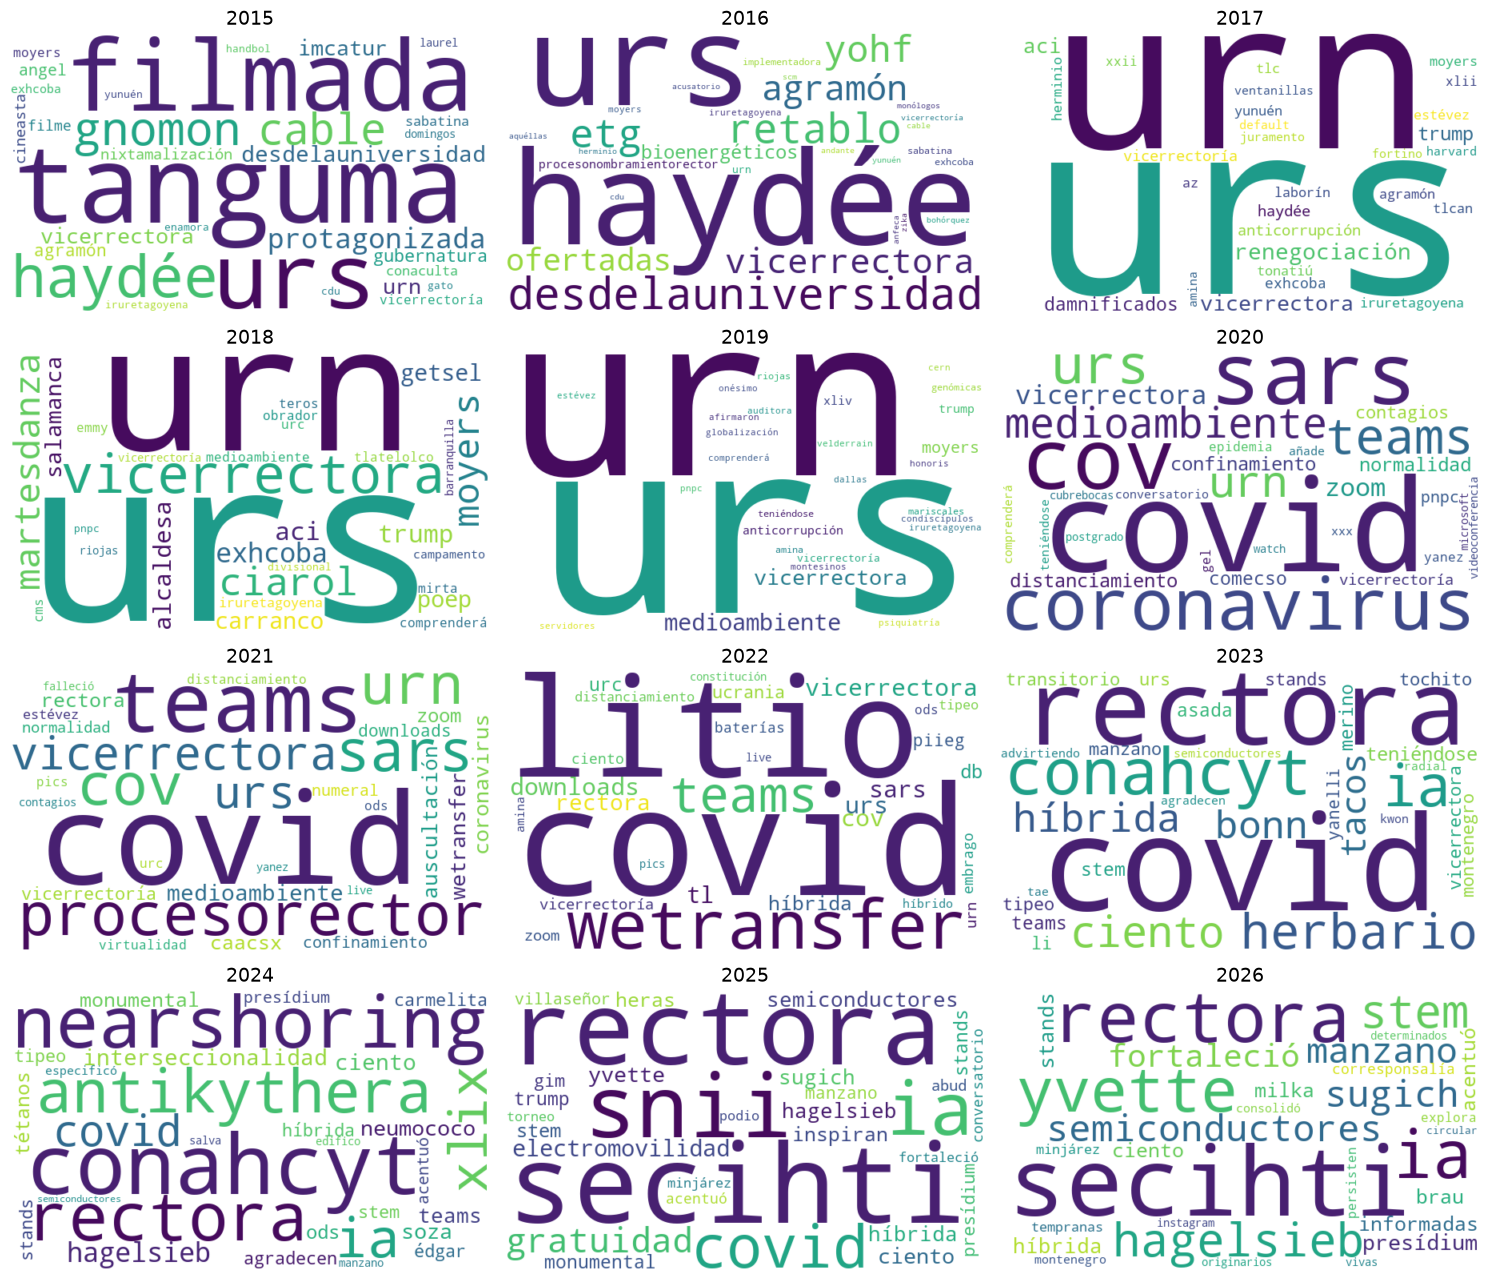

In [63]:
fig, ejes = plt.subplots(4, 3, figsize=(15, 13))

for anio, eje in zip(tfidf, ejes.flatten()):
    nube = WordCloud(width=600, height=350, background_color="white", random_state=42)
    nube.generate_from_frequencies(palabras_clave(anio, n=30, minimo_noticias=MINIMO_NOTICIAS_ANIO))
    eje.imshow(nube, interpolation="bilinear")
    eje.set_title(str(anio), fontsize=14)
    eje.axis("off")

plt.tight_layout()
plt.show()

### 8.6 Lo que TF-IDF no ve

*Pandemia* y *virtual* no salen en 2020–2021, aunque la sección 7 mostró que se dispararon. La razón está en el IDF:

In [64]:
for palabra in ["pandemia", "virtual"]:
    print(f"{palabra}: IDF = {idf[palabra]:.2f}")
    print("   veces por año:", {anio: veces_por_anio[anio][palabra] for anio in veces_por_anio})

pandemia: IDF = 0.00
   veces por año: {2015: 6, 2016: 1, 2017: 2, 2018: 1, 2019: 1, 2020: 474, 2021: 723, 2022: 501, 2023: 176, 2024: 66, 2025: 53, 2026: 17}
virtual: IDF = 0.00
   veces por año: {2015: 46, 2016: 30, 2017: 42, 2018: 36, 2019: 23, 2020: 450, 2021: 818, 2022: 322, 2023: 130, 2024: 86, 2025: 72, 2026: 62}


Basta con que una palabra aparezca **unas cuantas veces en cada año** (por ejemplo, *pandemia* 6 veces en 2015)
para que su IDF sea 0 y su TF-IDF también, por mucho que crezca después. Con años como documentos,
TF-IDF encuentra palabras **nuevas** en un periodo, no palabras que **crecen**. Por eso conviene combinarlo
con el seguimiento de la sección 7.

### 8.7 Seguimos las palabras que encontró TF-IDF

TF-IDF nos dio pistas; ahora las medimos con `porcentaje_por_anio` (sección 6.7).

In [65]:
descubiertas = pd.DataFrame({
    "Conacyt": porcentaje_por_anio(r"\bconacyt\b"),
    "Conahcyt": porcentaje_por_anio(r"\bconahcyt\b"),
    "Secihti": porcentaje_por_anio(r"\bsecihti\b"),
    "inteligencia artificial": porcentaje_por_anio("inteligencia artificial"),
    "semiconductores": porcentaje_por_anio("semiconductor"),
})
descubiertas.T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Conacyt,2.5,2.7,2.8,3.8,3.8,5.2,4.0,5.0,1.8,0.3,0.3,0.1
Conahcyt,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.9,1.7,0.5,0.2
Secihti,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.1,1.8
inteligencia artificial,0.3,0.1,0.3,0.3,2.3,2.1,3.2,1.1,2.8,3.7,6.1,6.6
semiconductores,0.2,0.1,0.0,0.2,0.5,0.1,0.1,0.4,1.6,1.3,2.5,3.1


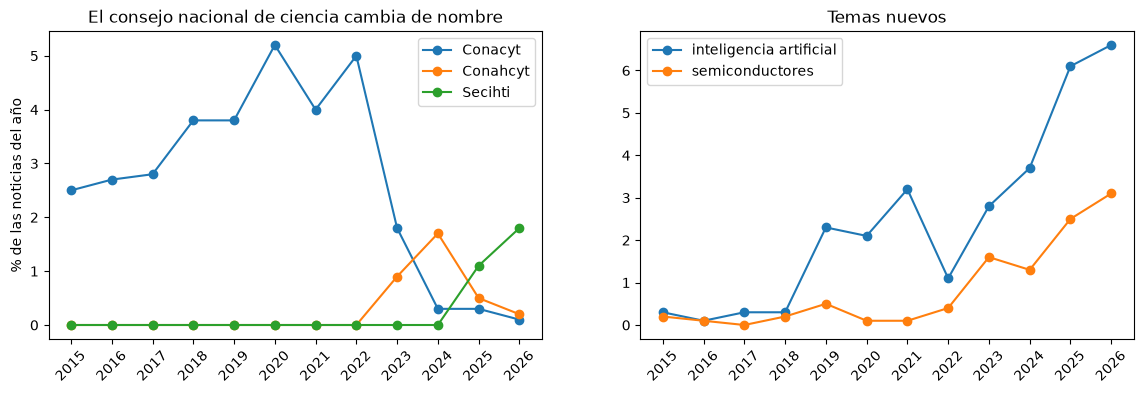

In [66]:
fig, (izquierda, derecha) = plt.subplots(1, 2, figsize=(14, 4))

for columna in ["Conacyt", "Conahcyt", "Secihti"]:
    izquierda.plot(descubiertas.index, descubiertas[columna], marker="o", label=columna)
izquierda.set_title("El consejo nacional de ciencia cambia de nombre")
izquierda.set_ylabel("% de las noticias del año")
izquierda.set_xticks(descubiertas.index)
izquierda.tick_params(axis="x", rotation=45)
izquierda.legend()

for columna in ["inteligencia artificial", "semiconductores"]:
    derecha.plot(descubiertas.index, descubiertas[columna], marker="o", label=columna)
derecha.set_title("Temas nuevos")
derecha.set_xticks(descubiertas.index)
derecha.tick_params(axis="x", rotation=45)
derecha.legend()

plt.show()

### Observaciones

- **TF-IDF hace solo lo que en la sección 5 hicimos a mano:** las palabras que aparecen todos los años
  (*universidad, estudiantes*) tienen IDF 0 y desaparecen sin tener que ampliar la lista de stopwords.
- **Primero encontró un problema en los datos:** las iniciales de los reporteros. Entre 2015 y 2017, ~85% de las notas
  terminan con *(JAR)*, *(BE)*, *(LMA)*...; en 2018 el 48%, y desde 2019 casi ninguna, porque se firman con el nombre completo.
  Las notas sí se firmaban antes de 2018.
- **Tres etapas** (después de quitar las iniciales):
  - **2015–2019, la universidad de antes:** *URS, URN* (Unidades Regionales Sur y Norte), la *vicerrectora* de la URS
    (Luz *Haydée* Cruz Morales) y directores de División (*Iruretagoyena*). En 2015–2016 el portal también publicaba
    la programación de la televisión universitaria: películas de Canal 8 (*filmada, protagonizada, cable*), su jefe
    (*Tanguma*) y el programa *Desde la Universidad*. Del contexto nacional: *Trump, renegociación* del TLCAN y
    *damnificados* de los sismos (2017), *anticorrupción*.
  - **2020–2022, la pandemia:** *covid, sars, cov, coronavirus, confinamiento, distanciamiento, normalidad*, y las
    herramientas a distancia: *Teams, Zoom, WeTransfer* (los enlaces de audio y fotos que acompañan las notas).
    En 2021 el proceso para elegir rector (*procesorector*); en 2022 la modalidad *híbrida*, el *litio* y *Ucrania*.
  - **2023–2026, la universidad de ahora:** *rectora*, *Conahcyt/Secihti, SNII, IA, STEM, semiconductores*,
    *nearshoring* (2024), *gratuidad* y *electromovilidad* (2025). La palabra *rector* aparecía en 7–14% de las notas
    hasta 2020; desde 2021 la universidad tiene rectora: María Rita Plancarte Martínez y, desde 2025, Dena María Camarena Gómez.
- **Otra vez un cambio de nombre (8.7):** el consejo nacional de ciencia pasa de *Conacyt* (2.5–5% de las notas hasta 2022)
  a *Conahcyt* (2023–2024) y a *Secihti* (2025–2026); el *SNI* pasa a *SNII*. TF-IDF los detecta justamente porque son
  nombres nuevos. Como con *Derecho* (6.7) y *Unidad Regional* (7.2), hay que revisar los nombres antes de concluir
  que un tema aparece o desaparece.
- **Temas que crecen de verdad:** *inteligencia artificial* pasa de ~0.3% de las notas (2015–2018) a 6.6% en 2026,
  y *semiconductores* de ~0.2% a 3.1%.

**Limitaciones:**
- Con años como documentos, una palabra presente en los 12 años tiene IDF 0: *pandemia* y *virtual* no salen en 2020–2021
  aunque se dispararon. TF-IDF encuentra palabras **nuevas**, no palabras que **crecen**; por eso lo complementamos
  con el seguimiento de la sección 7.
- También salen **nombres de personas** (funcionarios, académicos que dan entrevistas) y **palabras de estilo**
  de cada época (*medioambiente* escrito junto en 2019–2021; *acentuó, especificó, presídium* desde 2023).
  Dicen más de quién gobierna y quién escribe que de qué se habla.
- *ia* a veces es el Instituto de Astronomía, no inteligencia artificial.